# Spaceship Titanic Dataset

## Introduction

It is the future, and interstellar travel is becoming increasingly popular. The Spaceship Titanic is a new interstellar liner offering the opportunity to explore the stars for curious adventurers. However, even in an extremely advanced society, tragedies cannot be entirely avoided. The spaceship encountered an anomaly, and part of its passengers were transported to an alternative dimension! 

Parallel universes, or alternative dimensions, have fascinated scientists and science fiction enthusiasts for centuries. They are part of the multiverse theory, which suggests that our universe is not the only one and that many universes exist parallel to each other. These distinct universes within the multiverse framework are referred to as parallel universes (source: https://www.dummies.com/article/academics-the-arts/science/physics/the-theory-of-parallel-universes-193290/). Although now a proven concept, the multiverse theory still puzzles even the greatest minds of our time, and it is not entirely clear how or why such phenomena occur. To held identify which passengers were transported, we will use machine learning algorithms. 

**Dataset information**

Welcome to the year 2912, where your data science skills are needed to solve a cosmic mystery. We've received a transmission from four light years away and things aren't looking good.

The Spaceship Titanic was an interstellar passenger liner launched a month ago. With almost 13,000 passengers on board, the vessel set out on its maiden voyage transporting emigrants from our solar system to three newly habitable exoplanets orbiting nearby stars.

While rounding Alpha Centauri en route to its first destination—the torrid 55 Cancri E—the unwary Spaceship Titanic collided with a spacetime anomaly hidden within a dust cloud. Sadly, it met a similar fate as its namesake from 1000 years before. Though the ship stayed intact, almost half of the passengers were transported to an alternate dimension!

To help rescue crews and retrieve the lost passengers, you are challenged to predict which passengers were transported by the anomaly using records recovered from the spaceship’s damaged computer system.

Data is taken from Kaggle (https://www.kaggle.com/competitions/spaceship-titanic/overview).

**Project**

Spaceship Titanic competition dataset is used for Unsupervised Learning & Hyperparameter Tuning project of Machine Learning module sprint 3. Data analysis is done using python and pandas library. Modeling is done using scikit-learn. For visualization matplotlib and seaborn libraries were used. The project is done using Jupyter notebooks (4.2.4).

The project is done using python (version 3.11.4), numpy (2.0.1), seaborn (0.13.2), matplotlib (3.9.1), missingno (0.5.2), pandas (2.2.3), scikit-learn (1.5.1), scipy (1.14.0) and statsmodels (0.14.2)libraries.

**Project goal**

The goal of this project is to make a model which would predict if a passenger was transported to another dimension and to achieve a Kaggle submission score of 0.79 or higher.

**Plan**

First, I will do exploratory data analysis.

Second, I will check if the features are statistically important using hypothesis testing.

Third, I will create few models and tune their hyper-parameters. After tuning the best model will be chosen, based on accuracy score, as the goal is to predict as many people who were transported to another dimension as possible.

Lastly the best model will be used on test data to get predictions, which will be submitted to Kaggle competitions.

## Importing dataset and packages

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import missingno as msno
import warnings
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, FunctionTransformer, make_pipeline
from sklearn.preprocessing import OneHotEncoder
from scipy import stats
from scripts import *

In [2]:
data = pd.read_csv('data/train.csv')
data.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [3]:
test_data = pd.read_csv('data/test.csv')
test_data.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name
0,0013_01,Earth,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning
1,0018_01,Earth,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers
2,0019_01,Europa,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus
3,0021_01,Europa,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter
4,0023_01,Earth,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,0.0,Brence Harperez


In [4]:
print(f'Train dataset shape: {data.shape}')
print(f'Test dataset shape: {test_data.shape}')

Train dataset shape: (8693, 14)
Test dataset shape: (4277, 13)


## Checking for nulls and duplicates and other data cleaning

In [5]:
data.duplicated().any()

np.False_

In [6]:
nullresults = data.isnull().sum()
nullresults

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

In [7]:
for item in data.columns:
    print(f'The percentage of missing {item} values is {count_percentage(nullresults[item], data.shape[0])}%.')

The percentage of missing PassengerId values is 0.0%.
The percentage of missing HomePlanet values is 2.31%.
The percentage of missing CryoSleep values is 2.5%.
The percentage of missing Cabin values is 2.29%.
The percentage of missing Destination values is 2.09%.
The percentage of missing Age values is 2.06%.
The percentage of missing VIP values is 2.34%.
The percentage of missing RoomService values is 2.08%.
The percentage of missing FoodCourt values is 2.11%.
The percentage of missing ShoppingMall values is 2.39%.
The percentage of missing Spa values is 2.11%.
The percentage of missing VRDeck values is 2.16%.
The percentage of missing Name values is 2.3%.
The percentage of missing Transported values is 0.0%.


In [8]:
test_nullresults = test_data.isnull().sum()
test_nullresults

PassengerId       0
HomePlanet       87
CryoSleep        93
Cabin           100
Destination      92
Age              91
VIP              93
RoomService      82
FoodCourt       106
ShoppingMall     98
Spa             101
VRDeck           80
Name             94
dtype: int64

In [9]:
for item in test_data.columns:
    print(
        f'The percentage of missing {item} values is {count_percentage(test_nullresults[item], test_data.shape[0])}%.'
    )

The percentage of missing PassengerId values is 0.0%.
The percentage of missing HomePlanet values is 2.03%.
The percentage of missing CryoSleep values is 2.17%.
The percentage of missing Cabin values is 2.34%.
The percentage of missing Destination values is 2.15%.
The percentage of missing Age values is 2.13%.
The percentage of missing VIP values is 2.17%.
The percentage of missing RoomService values is 1.92%.
The percentage of missing FoodCourt values is 2.48%.
The percentage of missing ShoppingMall values is 2.29%.
The percentage of missing Spa values is 2.36%.
The percentage of missing VRDeck values is 1.87%.
The percentage of missing Name values is 2.2%.


Percentages of missing values in both test and data sets are similar.

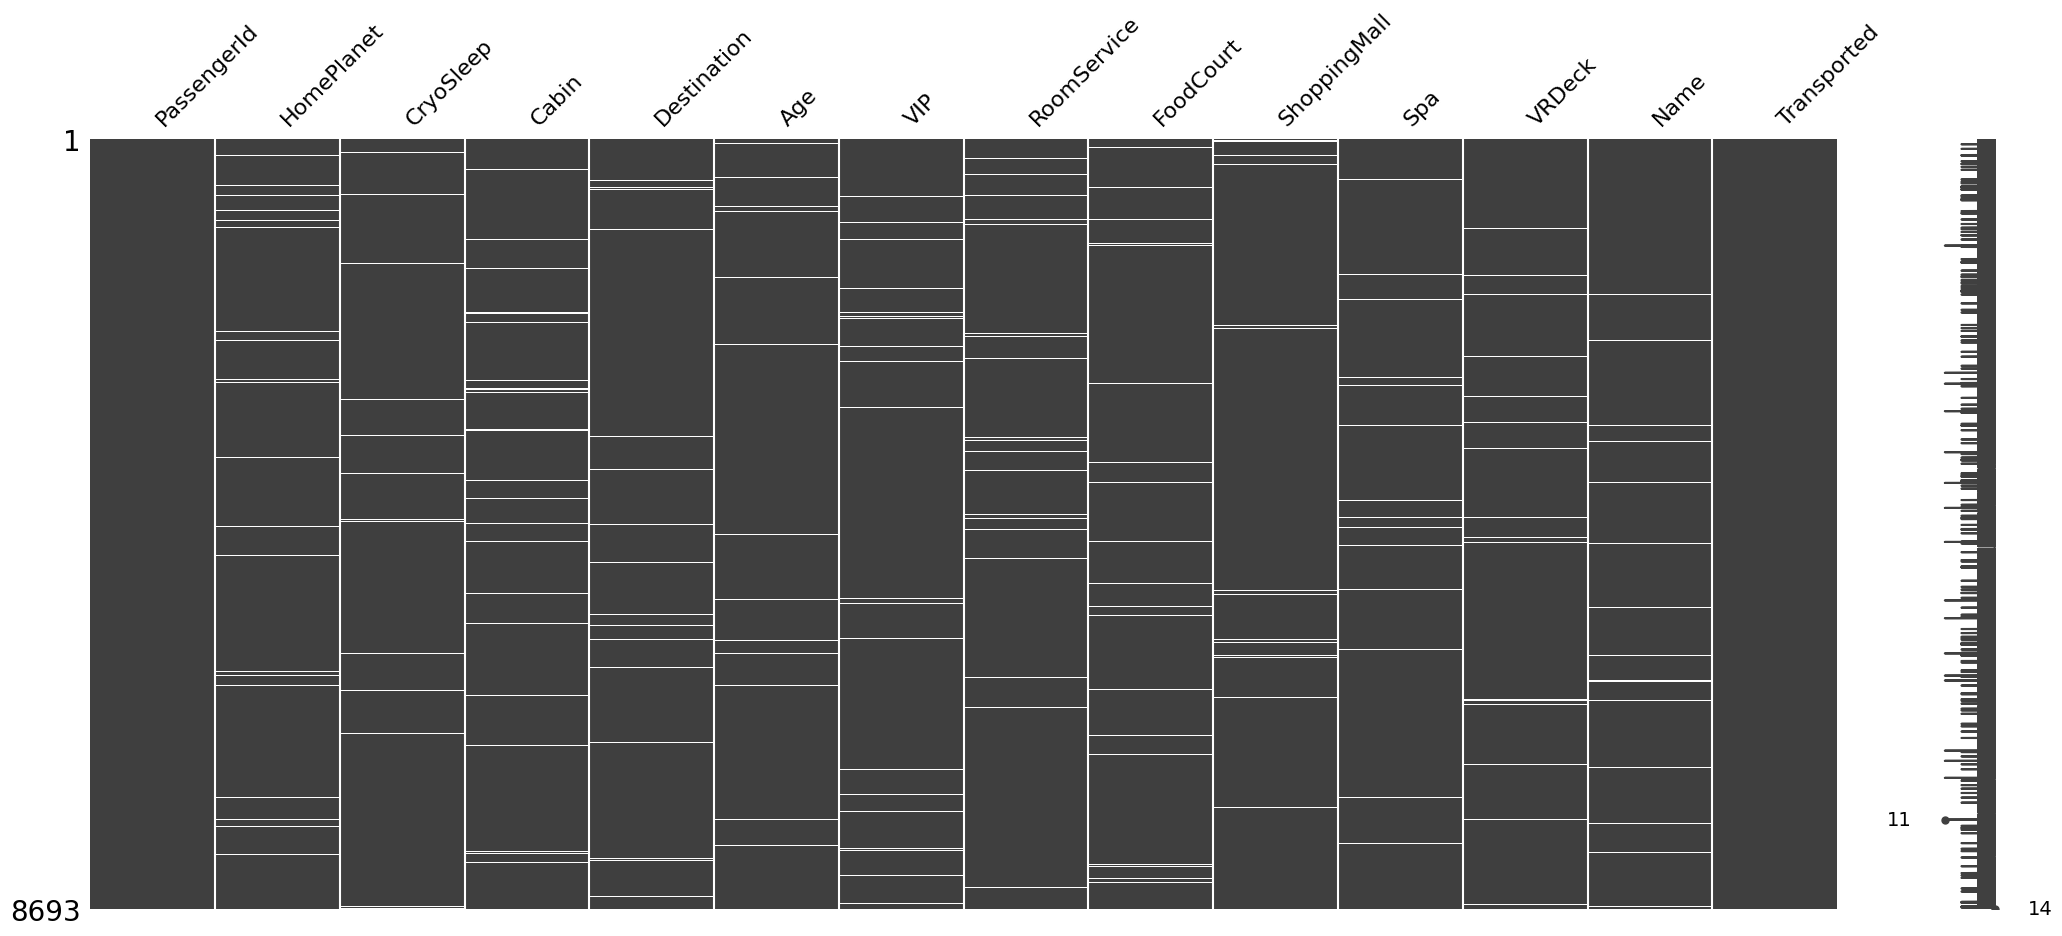

In [10]:
%matplotlib inline
msno.matrix(data);

There doesn't seem to be any patterns of missing values.
Missing values will be filled during modeling.

# Exploring data

## Features

In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


Attribute Information:

1) PassengerId - A unique Id for each passenger. Each Id takes the form gggg_pp where gggg indicates a group the passenger is traveling with and pp is their number within the group. People in a group are often family members, but not always.
2) HomePlanet - The planet the passenger departed from, typically their planet of permanent residence.
3) CryoSleep - Indicates whether the passenger elected to be put into suspended animation for the duration of the voyage. Passengers in cryo sleep are confined to their cabins.
4) Cabin - The cabin number where the passenger is staying. Takes the form deck/num/side, where side can be either P for Port or S for Starboard.
5) Destination - The planet the passenger will be debarking to.
6) Age - The age of the passenger.
7) VIP - Whether the passenger has paid for special VIP service during the voyage.
8) RoomService, FoodCourt, ShoppingMall, Spa, VRDeck - Amount the passenger has billed at each of the Spaceship Titanic's many luxury amenities.
9) Name - The first and last names of the passenger.
10) Transported - Whether the passenger was transported to another dimension. This is the target, the column you are trying to predict.

In [12]:
for i in data.columns:
    print(i, "column's total unique values are:", data[i].nunique())

PassengerId column's total unique values are: 8693
HomePlanet column's total unique values are: 3
CryoSleep column's total unique values are: 2
Cabin column's total unique values are: 6560
Destination column's total unique values are: 3
Age column's total unique values are: 80
VIP column's total unique values are: 2
RoomService column's total unique values are: 1273
FoodCourt column's total unique values are: 1507
ShoppingMall column's total unique values are: 1115
Spa column's total unique values are: 1327
VRDeck column's total unique values are: 1306
Name column's total unique values are: 8473
Transported column's total unique values are: 2


In [13]:
datac = data.copy()

features_cat = datac.select_dtypes(include=['object', 'int64', 'bool']).columns

for i in features_cat:
    print(i, "column's unique values are:", datac[i].unique())

PassengerId column's unique values are: ['0001_01' '0002_01' '0003_01' ... '9279_01' '9280_01' '9280_02']
HomePlanet column's unique values are: ['Europa' 'Earth' 'Mars' nan]
CryoSleep column's unique values are: [False True nan]
Cabin column's unique values are: ['B/0/P' 'F/0/S' 'A/0/S' ... 'G/1499/S' 'G/1500/S' 'E/608/S']
Destination column's unique values are: ['TRAPPIST-1e' 'PSO J318.5-22' '55 Cancri e' nan]
VIP column's unique values are: [False True nan]
Name column's unique values are: ['Maham Ofracculy' 'Juanna Vines' 'Altark Susent' ... 'Fayey Connon'
 'Celeon Hontichre' 'Propsh Hontichre']
Transported column's unique values are: [False  True]


In [14]:
datac[['deck', 'num', 'side']] = datac['Cabin'].str.split('/', expand=True)

for i in ['deck', 'num', 'side']:
    print(i, "column's total unique values are:", datac[i].nunique())

print()

for i in ['deck', 'num', 'side']:
    print(i, "column's unique values are:", datac[i].unique())

deck column's total unique values are: 8
num column's total unique values are: 1817
side column's total unique values are: 2

deck column's unique values are: ['B' 'F' 'A' 'G' nan 'E' 'D' 'C' 'T']
num column's unique values are: ['0' '1' '2' ... '1892' '1893' '1894']
side column's unique values are: ['P' 'S' nan]


In [15]:
datac[['group', 'number_in_group']] = datac['PassengerId'].str.split('_', expand=True)

for i in ['group', 'number_in_group']:
    print(i, "column's total unique values are:", datac[i].nunique())

print()

for i in ['group', 'number_in_group']:
    print(i, "column's unique values are:", datac[i].unique())

group column's total unique values are: 6217
number_in_group column's total unique values are: 8

group column's unique values are: ['0001' '0002' '0003' ... '9278' '9279' '9280']
number_in_group column's unique values are: ['01' '02' '03' '04' '05' '06' '07' '08']


In [16]:
datac['group_size'] = datac.groupby('group')['number_in_group'].transform(
    lambda x: datac.loc[x.idxmax(), 'number_in_group']
)
datac['total'] = datac[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].fillna(0).sum(axis=1)

datac.head().T

,0,1,2,3,4
PassengerId,0001_01,0002_01,0003_01,0003_02,0004_01
HomePlanet,Europa,Earth,Europa,Europa,Earth
CryoSleep,False,False,False,False,False
Cabin,B/0/P,F/0/S,A/0/S,A/0/S,F/1/S
Destination,TRAPPIST-1e,TRAPPIST-1e,TRAPPIST-1e,TRAPPIST-1e,TRAPPIST-1e
Age,39.0,24.0,58.0,33.0,16.0
VIP,False,False,True,False,False
RoomService,0.0,109.0,43.0,0.0,303.0
FoodCourt,0.0,9.0,3576.0,1283.0,70.0
ShoppingMall,0.0,25.0,0.0,371.0,151.0


In [17]:
datac['VIP'] = datac['VIP'].astype(float)
datac['CryoSleep'] = datac['CryoSleep'].astype(float)
datac['Transported'] = datac['Transported'].astype(int)
datac['group_size'] = datac['group_size'].astype(int)

In [18]:
group_trans_part = datac[['group', 'Transported']].groupby('group').mean()

fully_transported = group_trans_part[group_trans_part == 1]
some_transported = group_trans_part[group_trans_part > 0]

# selecting groups which have more one person
non1_group_trans_part = datac[['group', 'Transported']].loc[datac['group_size'] > 1].groupby('group').mean()
non1_fully_transported = non1_group_trans_part[non1_group_trans_part == 1]

count_full = fully_transported.Transported.count()
non1_count_full = non1_fully_transported.Transported.count()
count_some = some_transported.Transported.count()
all_groups = datac.group.count()

print(
    f'There were {count_full} fully transported groups, which is {count_percentage(count_full, all_groups)}% of all groups.'
)
print(
    f'Only {non1_count_full} of fully transported groups, had group size bigger than one, which is {count_percentage(non1_count_full, all_groups)}% of all groups.'
)
print(
    f'There were {count_some} partially transported groups, which is {count_percentage(count_some, all_groups)}% of all groups.'
)

There were 2552 fully transported groups, which is 29.36% of all groups.
Only 378 of fully transported groups, had group size bigger than one, which is 4.35% of all groups.
There were 3349 partially transported groups, which is 38.53% of all groups.


## Charts

### Categorical features

In [19]:
homeplanet_counts = datac['HomePlanet'].value_counts()
cryosleep_counts = datac['CryoSleep'].value_counts()
destination_counts = datac['Destination'].value_counts()
vip_counts = datac['VIP'].value_counts()
transported_counts = datac['Transported'].value_counts()
side_counts = datac['side'].value_counts()
deck_counts = datac['deck'].value_counts()

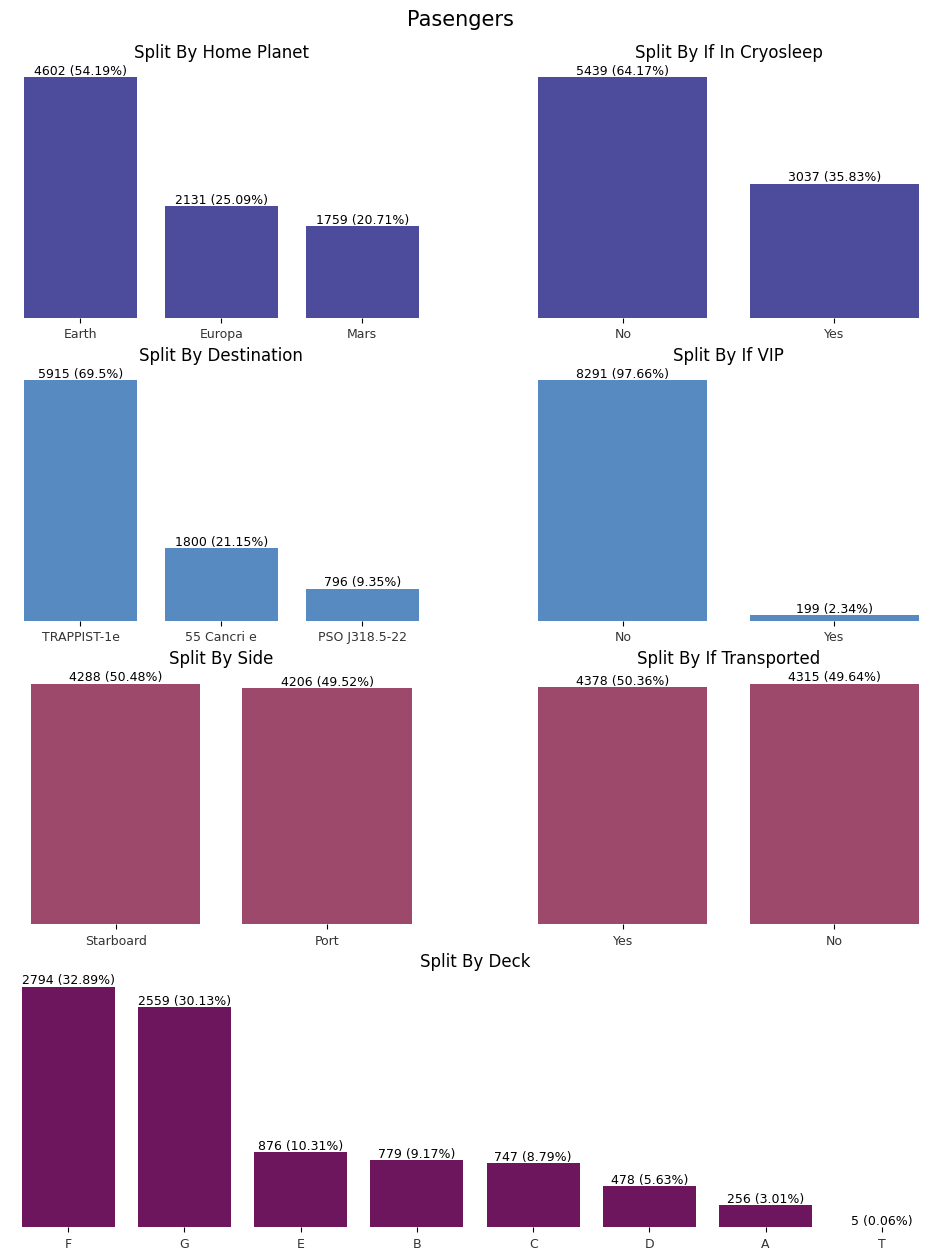

In [20]:
fig = plt.figure(figsize=(12, 14))

fig.suptitle('Pasengers', fontsize=15)
fig.subplots_adjust(top=0.94)

ax1 = plt.subplot2grid((4, 2), (0, 0), colspan=1)
ax1 = bar_plot_f_perc(homeplanet_counts, 'Split By Home Planet', color='#403eaa')
ax2 = plt.subplot2grid((4, 2), (0, 1), colspan=1)
ax2 = bar_plot_f_perc(cryosleep_counts, 'Split By If In Cryosleep', color='#403eaa')

ax3 = plt.subplot2grid((4, 2), (1, 0), colspan=1)
ax3 = bar_plot_f_perc(destination_counts, 'Split By Destination', color='#448ad3')
ax4 = plt.subplot2grid((4, 2), (1, 1), colspan=1)
ax4 = bar_plot_f_perc(vip_counts, 'Split By If VIP', color='#448ad3')

ax5 = plt.subplot2grid((4, 2), (2, 0), colspan=1)
ax5 = bar_plot_f_perc(side_counts, 'Split By Side', color='#aa3b6a')
ax6 = plt.subplot2grid((4, 2), (2, 1), colspan=1)
ax6 = bar_plot_f_perc(transported_counts, 'Split By If Transported', color='#aa3b6a')

ax7 = plt.subplot2grid((4, 2), (3, 0), colspan=2)
ax7 = bar_plot_f_perc(deck_counts, 'Split By Deck', color='#7b0867')

ax2.set_xticklabels(['No', 'Yes'])
ax4.set_xticklabels(['No', 'Yes'])
ax5.set_xticklabels(['Starboard', 'Port'])
ax6.set_xticklabels(['Yes', 'No'])
plt.tight_layout;

About half of the passengers were transported, however we can see that some of the categories are rare and therefore the dataset is unbalanced.

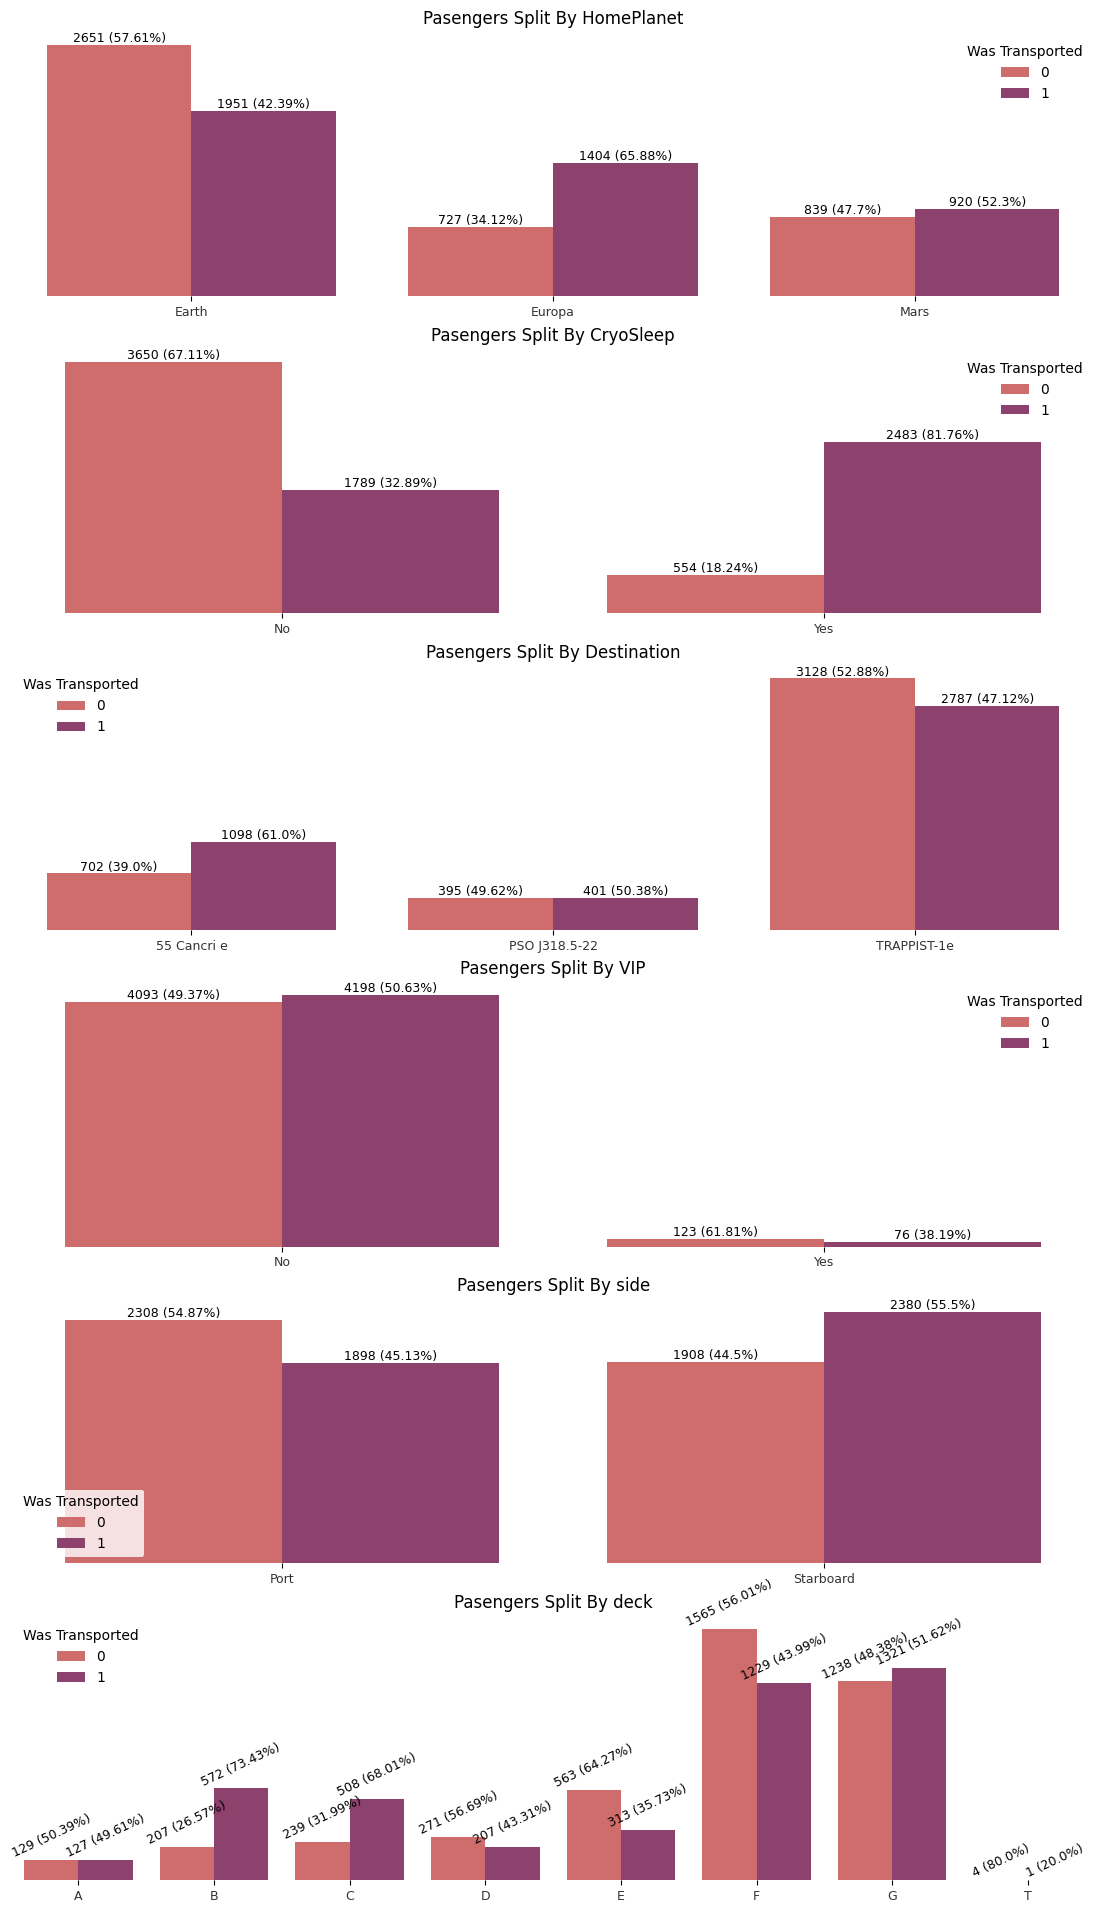

In [21]:
features = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'side', 'deck']

fig, axs = plt.subplots(len(features), 1, figsize=(14, (4 * len(features))))

palette = 'flare'

i = 0
for item in features:
    temp = datac.groupby(item)['Transported'].value_counts()
    if item in ['deck']:
        ax = bar_plot_multi_index_f(
            temp, item, 'Transported', f'Pasengers Split By {item}', palette, rotation=25, ax=axs[i]
        )
    else:
        ax = bar_plot_multi_index_f(temp, item, 'Transported', f'Pasengers Split By {item}', palette, ax=axs[i])
    ax.legend(edgecolor='none', title='Was Transported')
    if item in ['VIP', 'CryoSleep']:
        ax.set_xticklabels(['No', 'Yes'])
    if item in ['side']:
        ax.set_xticklabels(['Port', 'Starboard'])
    i += 1

There seems to be some tendencies who got transported, for example majority of people in decks B and C, and people in cryo sleep. There was a higher proportion of people on the starboard getting transported compared to the port. Destinations seems to matter as well, because there is a higher percentage passengers that got transported whose home planet is Europe and who is traveling to Cancri-e. Although there isn't many people who took VIP class, they had lower chances of getting transported. There were only 5 passengers recorded on deck T, 4 of them were not transported.

### Numerical features

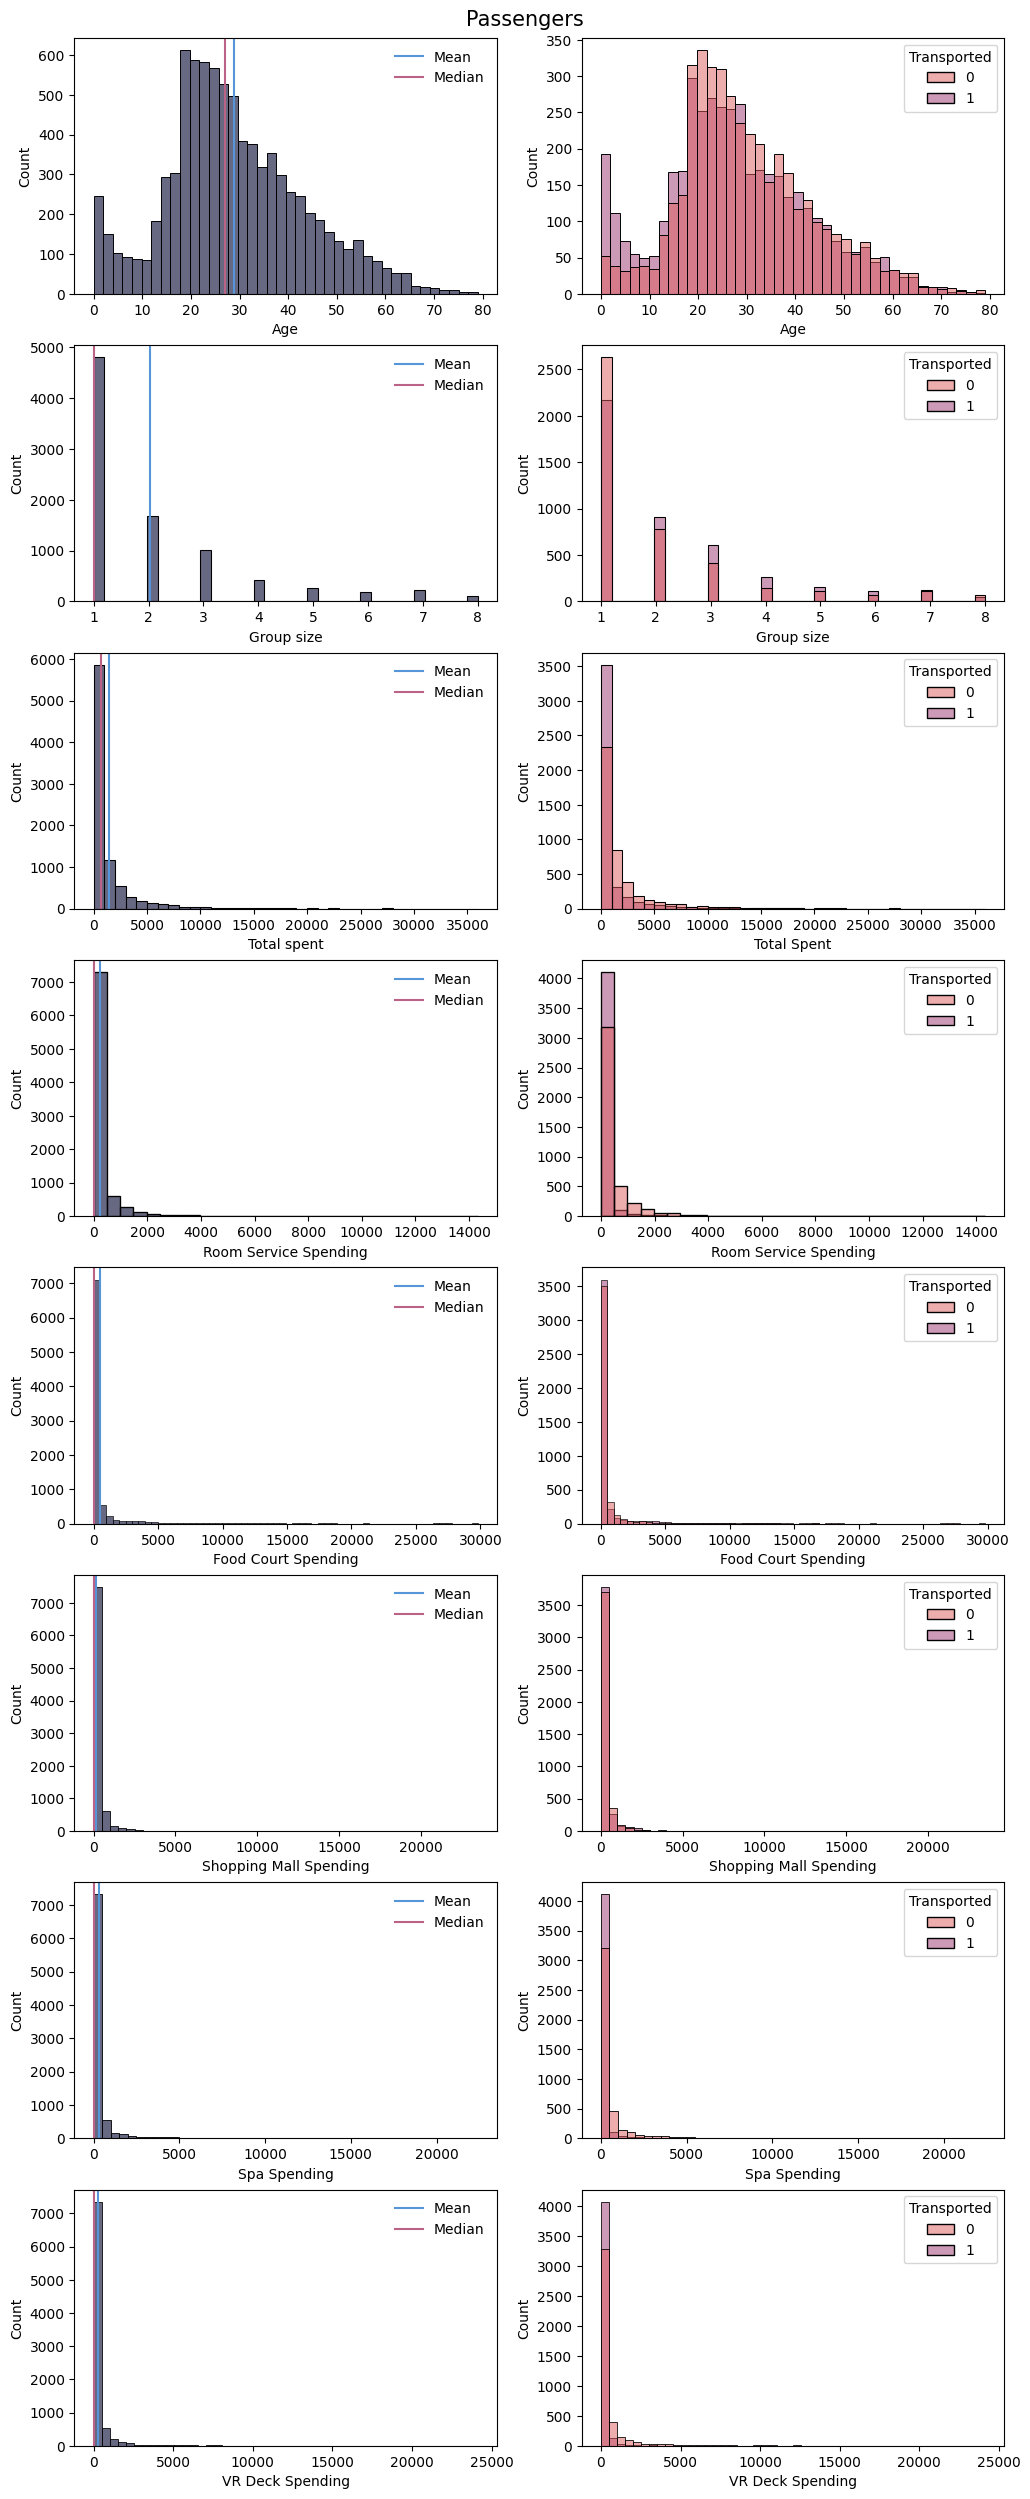

In [22]:
fig, axs = plt.subplots(8, 2, figsize=(12, 28))

fig.suptitle('Passengers', fontsize=15)
fig.subplots_adjust(top=0.97)

palette = 'flare'

ax00 = histplot_f(datac.Age, color='#343557', color_median='#bb6287', color_mean='#5695d7', binwidth=2, ax=axs[0, 0])
ax00.set(xlabel='Age')
ax01 = simple_histplot(datac, 'Age', xlabel='Age', hue='Transported', palette=palette, binwidth=2, ax=axs[0, 1])

ax10 = histplot_f(datac.group_size, color='#343557', color_median='#bb6287', color_mean='#5695d7', ax=axs[1, 0])
ax10.set(xlabel='Group size')
ax11 = simple_histplot(datac, 'group_size', xlabel='Group size', hue='Transported', palette=palette, ax=axs[1, 1])

ax20 = histplot_f(
    datac.total, color='#343557', color_median='#bb6287', color_mean='#5695d7', binwidth=1000, ax=axs[2, 0]
)
ax20.set(xlabel='Total spent')
ax21 = simple_histplot(
    datac, 'total', xlabel='Total Spent', hue='Transported', palette=palette, binwidth=1000, ax=axs[2, 1]
)

ax30 = histplot_f(
    datac.RoomService, color='#343557', color_median='#bb6287', color_mean='#5695d7', binwidth=500, ax=axs[3, 0]
)
ax30.set(xlabel='Room Service Spending')
ax31 = simple_histplot(
    datac, 'RoomService', xlabel='Room Service Spending', hue='Transported', binwidth=500, palette=palette, ax=axs[3, 1]
)

ax40 = histplot_f(
    datac.FoodCourt, color='#343557', color_median='#bb6287', color_mean='#5695d7', binwidth=500, ax=axs[4, 0]
)
ax40.set(xlabel='Food Court Spending')
ax41 = simple_histplot(
    datac, 'FoodCourt', xlabel='Food Court Spending', hue='Transported', binwidth=500, palette=palette, ax=axs[4, 1]
)

ax50 = histplot_f(
    datac.ShoppingMall, color='#343557', color_median='#bb6287', color_mean='#5695d7', binwidth=500, ax=axs[5, 0]
)
ax50.set(xlabel='Shopping Mall Spending')
ax51 = simple_histplot(
    datac,
    'ShoppingMall',
    xlabel='Shopping Mall Spending',
    hue='Transported',
    binwidth=500,
    palette=palette,
    ax=axs[5, 1],
)

ax60 = histplot_f(datac.Spa, color='#343557', color_median='#bb6287', color_mean='#5695d7', binwidth=500, ax=axs[6, 0])
ax60.set(xlabel='Spa Spending')
ax61 = simple_histplot(
    datac, 'Spa', xlabel='Spa Spending', hue='Transported', binwidth=500, palette=palette, ax=axs[6, 1]
)

ax70 = histplot_f(
    datac.VRDeck, color='#343557', color_median='#bb6287', color_mean='#5695d7', binwidth=500, ax=axs[7, 0]
)
ax70.set(xlabel='VR Deck Spending')
ax71 = simple_histplot(
    datac, 'VRDeck', xlabel='VR Deck Spending', hue='Transported', binwidth=500, palette=palette, ax=axs[7, 1]
)

We can see that there is a higher proportion of kids and teens being transported compared to older people. Majority of passengers traveled in groups of 1. There is a higher chance that someone was transported if the group is bigger in size. Majority of people didn't spend money on anything or spend very little.

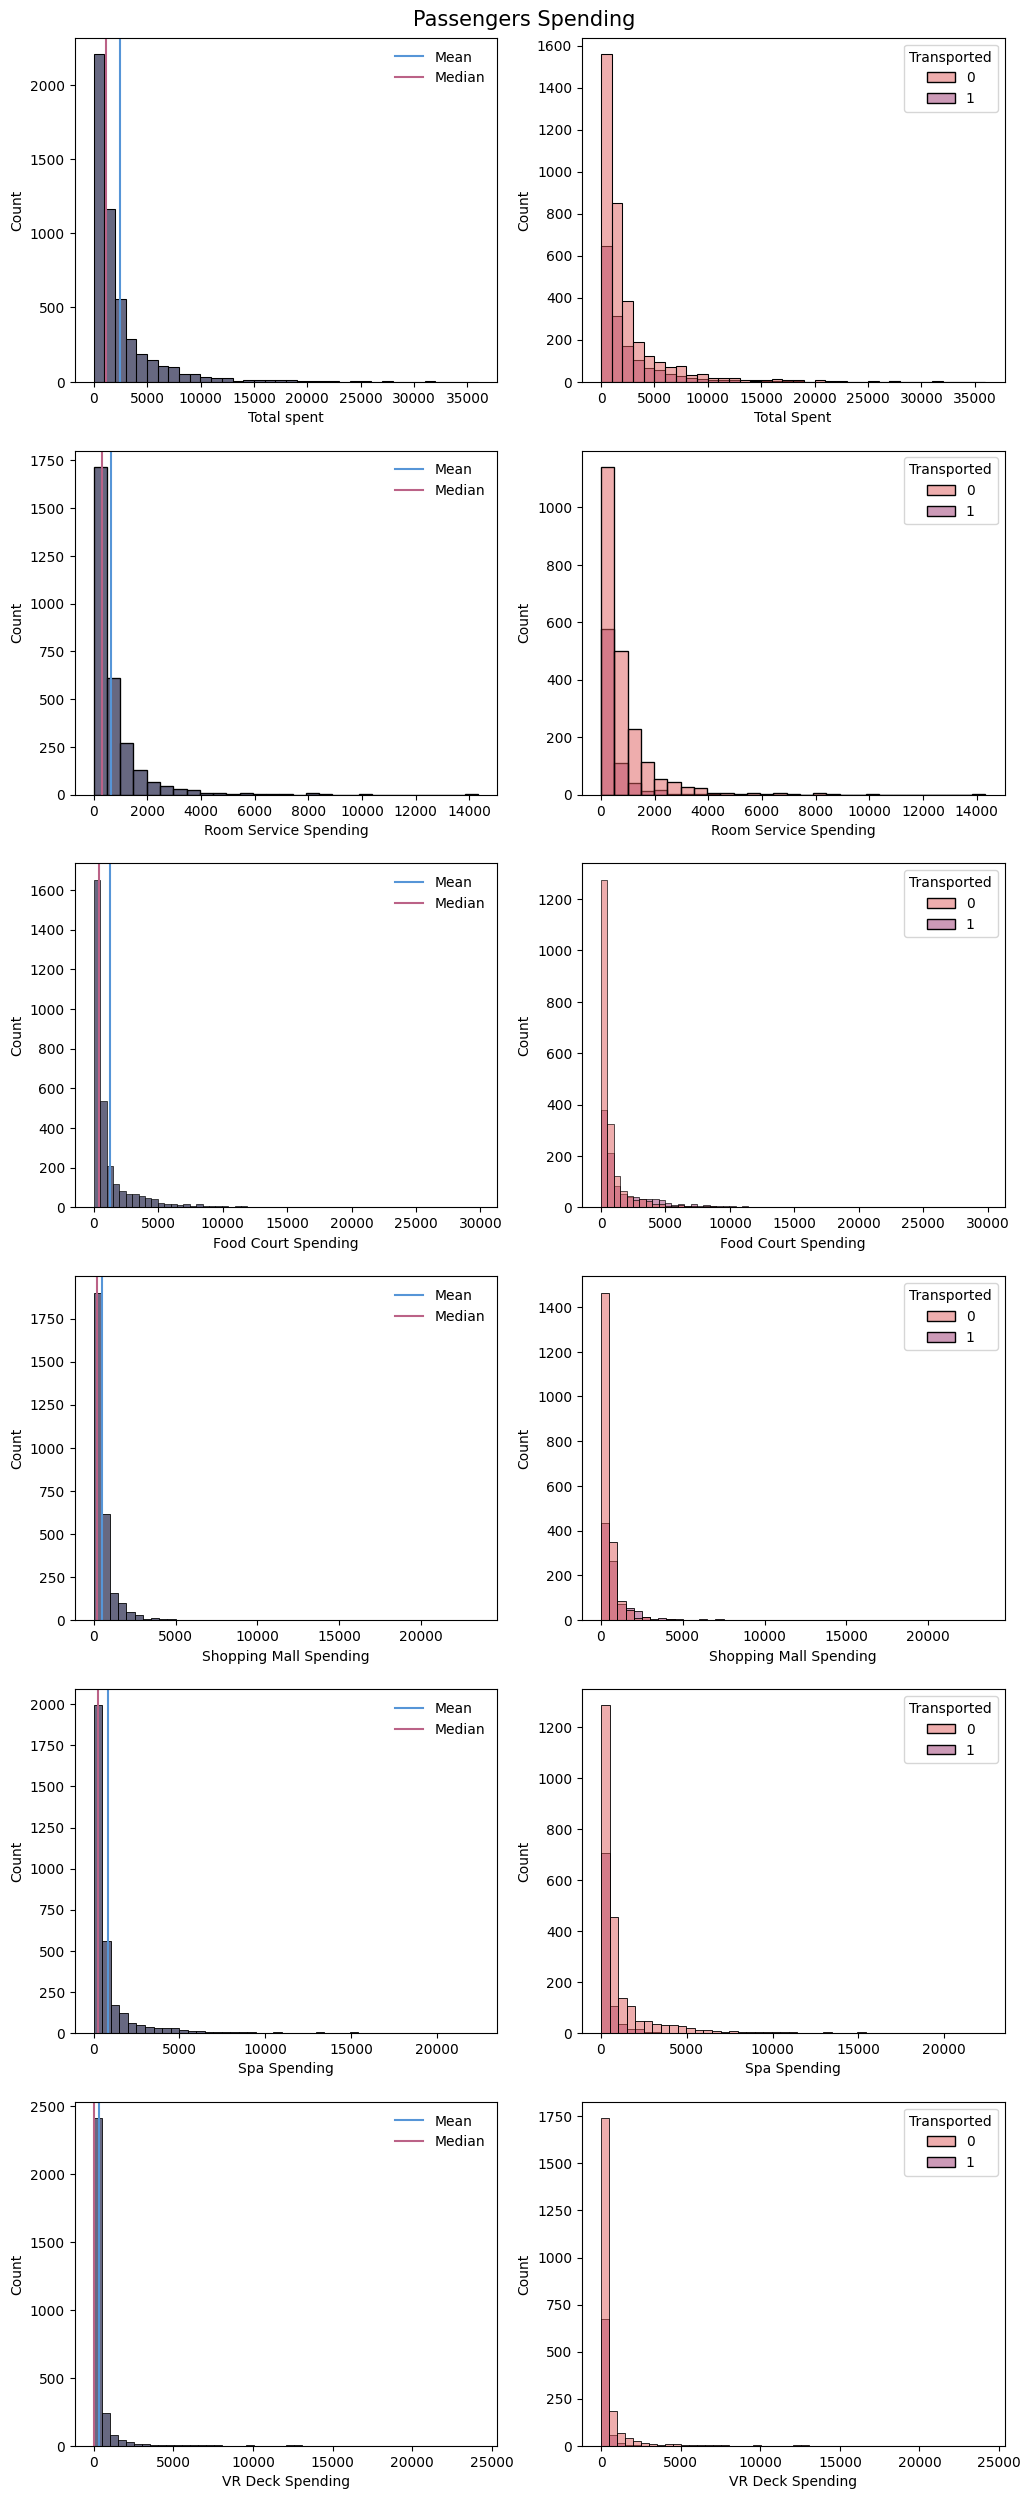

In [23]:
fig, axs = plt.subplots(6, 2, figsize=(12, 28))

fig.suptitle('Passengers Spending', fontsize=15)
fig.subplots_adjust(top=0.97)

palette = 'flare'

total_nonzero = datac[['total', 'Transported']].loc[datac.total > 0]
ax00 = histplot_f(
    total_nonzero.total, color='#343557', color_median='#bb6287', color_mean='#5695d7', binwidth=1000, ax=axs[0, 0]
)
ax00.set(xlabel='Total spent')
ax01 = simple_histplot(
    total_nonzero, 'total', xlabel='Total Spent', hue='Transported', palette=palette, binwidth=1000, ax=axs[0, 1]
)

roomservice_nonzero = datac[['RoomService', 'Transported']].loc[datac.RoomService > 0]
ax10 = histplot_f(
    roomservice_nonzero.RoomService,
    color='#343557',
    color_median='#bb6287',
    color_mean='#5695d7',
    binwidth=500,
    ax=axs[1, 0],
)
ax10.set(xlabel='Room Service Spending')
ax11 = simple_histplot(
    roomservice_nonzero,
    'RoomService',
    xlabel='Room Service Spending',
    hue='Transported',
    binwidth=500,
    palette=palette,
    ax=axs[1, 1],
)

foodcourt_nonzero = datac[['FoodCourt', 'Transported']].loc[datac.FoodCourt > 0]
ax20 = histplot_f(
    foodcourt_nonzero.FoodCourt,
    color='#343557',
    color_median='#bb6287',
    color_mean='#5695d7',
    binwidth=500,
    ax=axs[2, 0],
)
ax20.set(xlabel='Food Court Spending')
ax21 = simple_histplot(
    foodcourt_nonzero,
    'FoodCourt',
    xlabel='Food Court Spending',
    hue='Transported',
    binwidth=500,
    palette=palette,
    ax=axs[2, 1],
)

shoppingmall_nonzero = datac[['ShoppingMall', 'Transported']].loc[datac.ShoppingMall > 0]
ax30 = histplot_f(
    shoppingmall_nonzero.ShoppingMall,
    color='#343557',
    color_median='#bb6287',
    color_mean='#5695d7',
    binwidth=500,
    ax=axs[3, 0],
)
ax30.set(xlabel='Shopping Mall Spending')
ax31 = simple_histplot(
    shoppingmall_nonzero,
    'ShoppingMall',
    xlabel='Shopping Mall Spending',
    hue='Transported',
    binwidth=500,
    palette=palette,
    ax=axs[3, 1],
)

spa_nonzero = datac[['Spa', 'Transported']].loc[datac.Spa > 0]
ax40 = histplot_f(
    spa_nonzero.Spa, color='#343557', color_median='#bb6287', color_mean='#5695d7', binwidth=500, ax=axs[4, 0]
)
ax40.set(xlabel='Spa Spending')
ax41 = simple_histplot(
    spa_nonzero, 'Spa', xlabel='Spa Spending', hue='Transported', binwidth=500, palette=palette, ax=axs[4, 1]
)

vrdeck_nonzero = datac[['VRDeck', 'Transported']].loc[datac.RoomService > 0]
ax50 = histplot_f(
    vrdeck_nonzero.VRDeck, color='#343557', color_median='#bb6287', color_mean='#5695d7', binwidth=500, ax=axs[5, 0]
)
ax50.set(xlabel='VR Deck Spending')
ax51 = simple_histplot(
    vrdeck_nonzero, 'VRDeck', xlabel='VR Deck Spending', hue='Transported', binwidth=500, palette=palette, ax=axs[5, 1]
)

All of the graphs have right skewed distribution with majority of passengers spending not that much money on attractions. We can also see that in most cases spending more or less money does not make too much of a difference if you were transported or not. Exception is that we can see small tendency that people who spend more in shopping mall and food court were more likely to be transported.

## Feature engineering

### Determining if the person has spend money or not

In [24]:
datac['spent_money'] = datac['total'].apply(lambda x: 1 if x > 0 else 0)
datac['spent_on_room_service'] = datac['RoomService'].apply(lambda x: 1 if x > 0 else 0)
datac['spent_in_food_court'] = datac['FoodCourt'].apply(lambda x: 1 if x > 0 else 0)
datac['spent_in_shopping_mall'] = datac['ShoppingMall'].apply(lambda x: 1 if x > 0 else 0)
datac['spent_on_spa'] = datac['Spa'].apply(lambda x: 1 if x > 0 else 0)
datac['spent_in_vr_deck'] = datac['VRDeck'].apply(lambda x: 1 if x > 0 else 0)

spent_money_counts = datac['spent_money'].value_counts().sort_values()
spent_money_counts_transported = datac.groupby('spent_money')['Transported'].value_counts()

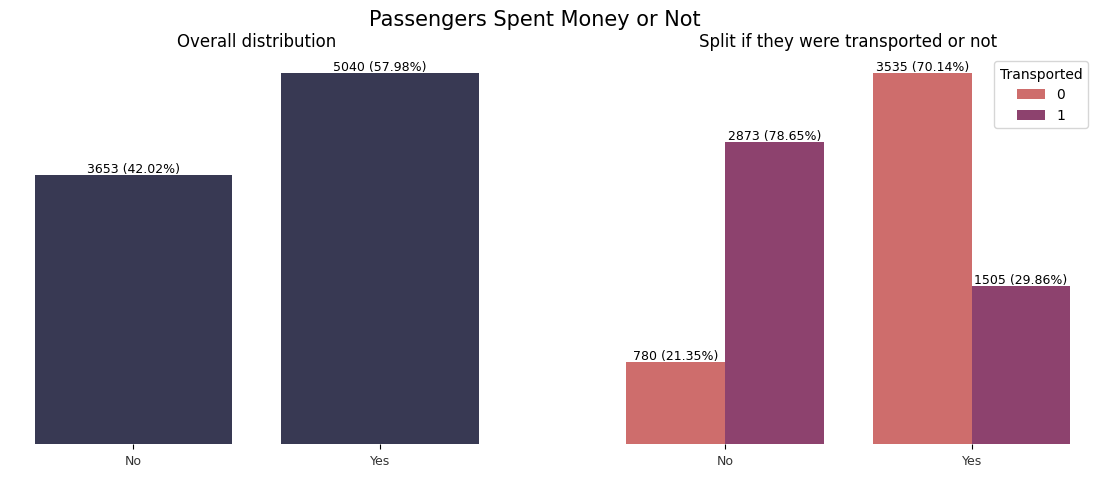

In [25]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

fig.suptitle('Passengers Spent Money or Not', fontsize=15)
fig.subplots_adjust(top=0.89)

palette = 'flare'

ax1 = bar_plot_f_perc(spent_money_counts, 'Overall distribution', color='#343557', ax=axs[0])
ax2 = bar_plot_multi_index_f(
    spent_money_counts_transported,
    'spent_money',
    'Transported',
    'Split if they were transported or not',
    palette,
    ax=axs[1],
)

ax1.set_xticklabels(['No', 'Yes'])
ax2.set_xticklabels(['No', 'Yes']);

There are more people who have spent any money on any of the attractions than there are not. Also there are more people who have been transported who didn't spend anything compared to these who did. It might be connected to specific location at the spaceship or the age of the buyers, since, for example children were transported more often.

In [26]:
datac.describe().T

,count,mean,std,min,25%,50%,75%,max
CryoSleep,8476.0,0.358306,0.479531,0.0,0.0,0.0,1.0,1.0
Age,8514.0,28.827930,14.489021,0.0,19.0,27.0,38.0,79.0
VIP,8490.0,0.023439,0.151303,0.0,0.0,0.0,0.0,1.0
RoomService,8512.0,224.687617,666.717663,0.0,0.0,0.0,47.0,14327.0
FoodCourt,8510.0,458.077203,1611.489240,0.0,0.0,0.0,76.0,29813.0
ShoppingMall,8485.0,173.729169,604.696458,0.0,0.0,0.0,27.0,23492.0
Spa,8510.0,311.138778,1136.705535,0.0,0.0,0.0,59.0,22408.0
VRDeck,8505.0,304.854791,1145.717189,0.0,0.0,0.0,46.0,24133.0
Transported,8693.0,0.503624,0.500016,0.0,0.0,1.0,1.0,1.0
group_size,8693.0,2.035546,1.596347,1.0,1.0,1.0,3.0,8.0


### One-hot encoding categorical features

The columns with too many unique values will be dropped, as they won't be used in the future analysis. Also it is unlikely that anomaly managed to choose persons depending on their cabin number, name or passengerId.

In [27]:
col_to_drop = ['Cabin', 'PassengerId', 'Name', 'num', 'group', 'number_in_group']
datac = datac.drop(col_to_drop, axis=1)

x_num = datac.select_dtypes(exclude='object').reset_index(drop=True)
x_cat = datac.select_dtypes(include='object')

encoder = OneHotEncoder(sparse_output=False)
x_encoded = encoder.fit_transform(x_cat)

# create the names for the one-hot encoded categorical features
categorical_columns = [f'{col}_{cat}' for i, col in enumerate(x_cat.columns) for cat in encoder.categories_[i]]

# put the features into a dataframe and join with the original
# numerical features

one_hot_features = pd.DataFrame(x_encoded, columns=categorical_columns)
one_hot_features = one_hot_features.drop(['HomePlanet_nan', 'Destination_nan', 'deck_nan', 'side_nan'], axis=1)
datac_enc = x_num.join(one_hot_features)

# Putting Transported column last for convience
cols = datac_enc.columns.tolist()
cols = cols[:8] + cols[9:] + cols[8:9]

datac_enc = datac_enc[cols]
datac_enc.head(10).T

,0,1,2,3,4,5,6,7,8,9
CryoSleep,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
Age,39.0,24.0,58.0,33.0,16.0,44.0,26.0,28.0,35.0,14.0
VIP,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
RoomService,0.0,109.0,43.0,0.0,303.0,0.0,42.0,0.0,0.0,0.0
FoodCourt,0.0,9.0,3576.0,1283.0,70.0,483.0,1539.0,0.0,785.0,0.0
ShoppingMall,0.0,25.0,0.0,371.0,151.0,0.0,3.0,0.0,17.0,0.0
Spa,0.0,549.0,6715.0,3329.0,565.0,291.0,0.0,0.0,216.0,0.0
VRDeck,0.0,44.0,49.0,193.0,2.0,0.0,0.0,NaN,0.0,0.0
group_size,1.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,3.0
total,0.0,736.0,10383.0,5176.0,1091.0,774.0,1584.0,0.0,1018.0,0.0


## Correlation

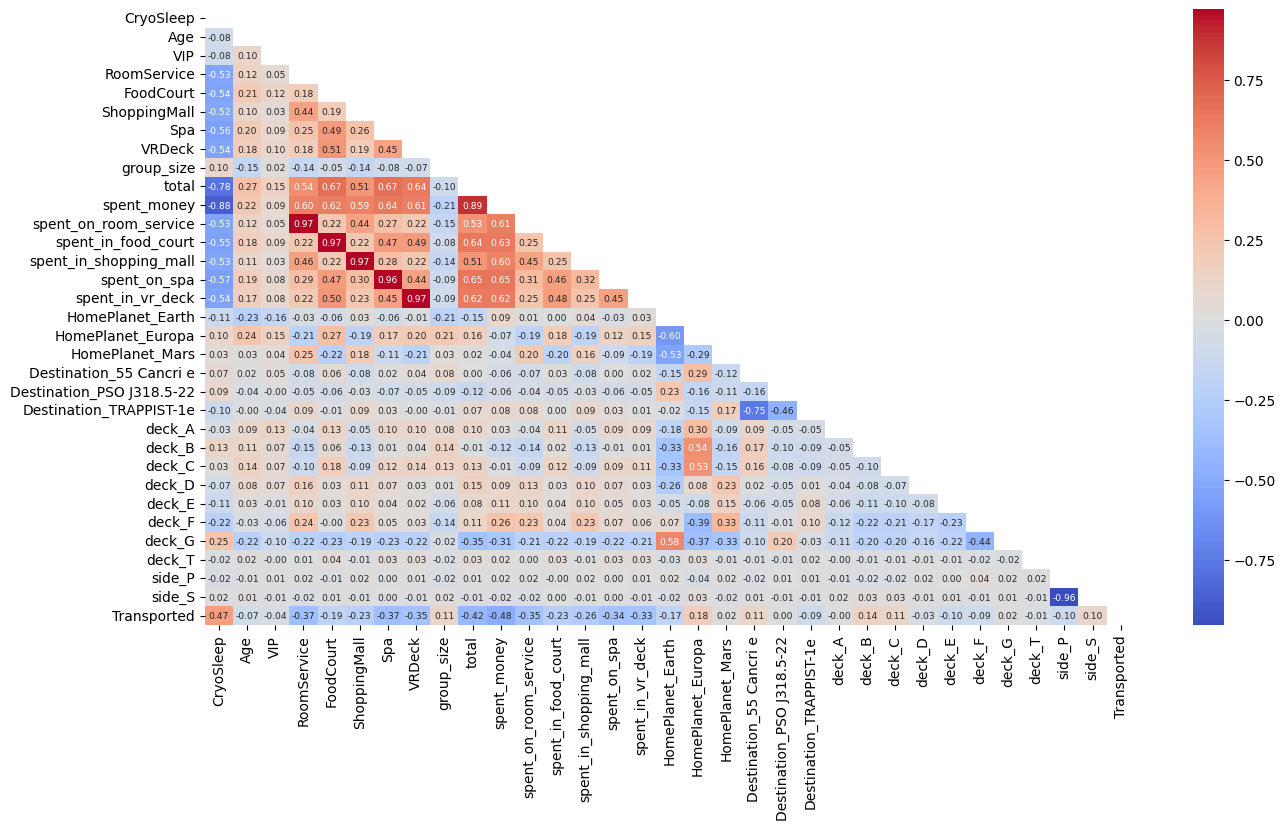

In [28]:
# Spearman correlation assumes monotonic relationships
corr = datac_enc.corr(method='spearman')

fig = plt.figure(figsize=(15, 8))

# To make a triangle mask
mask = np.triu(np.ones_like(corr))

corr_plot = sns.heatmap(
    corr,
    cmap=sns.color_palette("coolwarm", as_cmap=True),
    annot=True,
    annot_kws={"size": 38 / np.sqrt(len(corr))},
    fmt=".2f",
    mask=mask,
)

Spearman correlation was used to have a quick picture of overall tendencies in correlations. There are some expected results, such as people in cryo sleep are not spending as much money, compared to ones who aren't (negative correlation). Bigger group size also indicates lower spending, as families are usually (but not always) in one group and travel together, children are not as likely to spend money (weak negative correlation for group size vs spending). We can see that spending correlate with positively with age. There are strong positive and negative correlations for extracted features (such as side S vs side P, total vs spent money which, and  et cetera).

For binary values it is better to use Point-Biserial and Kendall tau correlation coefficients. The Point-Biserial index is used when one variable is numeric and the other is binary. The Kendall tau coefficient is a statistic used to measure the ordinal association between two measured quantities. It can be used when both values are binary. Thus, to analyze transported or not passengers, both Point-Biserial and Kendall’s Tau correlations will be used to ensure a more accurate assessment.

In [29]:
nonbinary_list = []
binary_list = []

for i in datac_enc.columns[:-1]:
    if datac_enc[i].nunique() > 2:
        nonbinary_list.append(i)
    else:
        binary_list.append(i)

nonbinary_list
binary_list

print(nonbinary_list)
print(binary_list)

['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'group_size', 'total']
['CryoSleep', 'VIP', 'spent_money', 'spent_on_room_service', 'spent_in_food_court', 'spent_in_shopping_mall', 'spent_on_spa', 'spent_in_vr_deck', 'HomePlanet_Earth', 'HomePlanet_Europa', 'HomePlanet_Mars', 'Destination_55 Cancri e', 'Destination_PSO J318.5-22', 'Destination_TRAPPIST-1e', 'deck_A', 'deck_B', 'deck_C', 'deck_D', 'deck_E', 'deck_F', 'deck_G', 'deck_T', 'side_P', 'side_S']


In [30]:
biserial_c = []
biserial_c_p = []
for i in nonbinary_list:
    temp1 = datac_enc[i].dropna()
    temp1.index
    temp2 = datac_enc.Transported[temp1.index]
    biserial = stats.pointbiserialr(temp1, temp2)
    biserial_c.append(biserial[0])
    biserial_c_p.append(biserial[1])

dictionary = {'Correlation': biserial_c, 'p_value': biserial_c_p}

dfbiserial = pd.DataFrame(dictionary, index=nonbinary_list)
dfbiserial.style.background_gradient(subset=["Correlation"])

,Correlation,p_value
Age,-0.075026,0.000000
RoomService,-0.244611,0.000000
FoodCourt,0.046566,0.000017
ShoppingMall,0.010141,0.350301
Spa,-0.221131,0.000000
VRDeck,-0.207075,0.000000
group_size,0.082644,0.000000
total,-0.199514,0.000000


We can see that there are some negative correlations between being transported and spending money for room service, at spa and VR deck, and total spending. All of the p values are rather low (lower than 0.05), expect for correlation results for spending at the shopping mall, indicating that this result is not statistically significant. 

In [31]:
kendalltau_c = []
kendalltau_c_p = []
for i in binary_list:
    temp1 = datac_enc[i].dropna()
    temp1.index
    temp2 = datac_enc.Transported[temp1.index]
    kendalltau = stats.kendalltau(temp1, temp2)
    kendalltau_c.append(kendalltau[0])
    kendalltau_c_p.append(kendalltau[1])

dictionary = {'Correlation': kendalltau_c, 'p_value': kendalltau_c_p}

dfkendalltau = pd.DataFrame(dictionary, index=binary_list)
dfkendalltau.style.background_gradient(subset=["Correlation"])

,Correlation,p_value
CryoSleep,0.468645,0.000000
VIP,-0.037650,0.000523
spent_money,-0.481628,0.000000
spent_on_room_service,-0.347928,0.000000
spent_in_food_court,-0.232816,0.000000
spent_in_shopping_mall,-0.263792,0.000000
spent_on_spa,-0.344050,0.000000
spent_in_vr_deck,-0.332175,0.000000
HomePlanet_Earth,-0.169019,0.000000
HomePlanet_Europa,0.176916,0.000000


We can see positive correlation between cryo sleep being transported (0.46). Also there are negative correlations with spending money at any of the attractions and being transported (lower than -0.23). There are also weak positive correlations for home planet Europa, destination 55 Cancri e, decks B and C, and being on Starboard side (0.1 - 0.2). There are weak negative correlations for home planet Earth, being on Port side, destination TRAPPIST-1e, decks E and F (-0.17 - -0.08). These correlations might indicate certain locations on the star ship which were more affected by the anomaly than other. For example, leaving your cabin and going to any of the attractions, gives you better chances to not be transported by the anomaly, compared to passengers who were in cryo sleep and not moving.

## Outliers

In [32]:
outliers = outlier_f(datac_enc)
outliers.count()

CryoSleep                       0
Age                            77
VIP                           199
RoomService                  1861
FoodCourt                    1823
ShoppingMall                 1829
Spa                          1788
VRDeck                       1809
group_size                    335
total                         934
spent_money                     0
spent_on_room_service           0
spent_in_food_court             0
spent_in_shopping_mall          0
spent_on_spa                    0
spent_in_vr_deck                0
HomePlanet_Earth                0
HomePlanet_Europa            2131
HomePlanet_Mars              1759
Destination_55 Cancri e      1800
Destination_PSO J318.5-22     796
Destination_TRAPPIST-1e         0
deck_A                        256
deck_B                        779
deck_C                        747
deck_D                        478
deck_E                        876
deck_F                          0
deck_G                          0
deck_T        

Outliers for home planets and destinations are there just because majority of people traveled from Earth, and some of the destinations were not as popular. Outliers in decks are also because there are a lot of different decks and there have been different amount of people staying at each. All VIP passengers are also outliers.

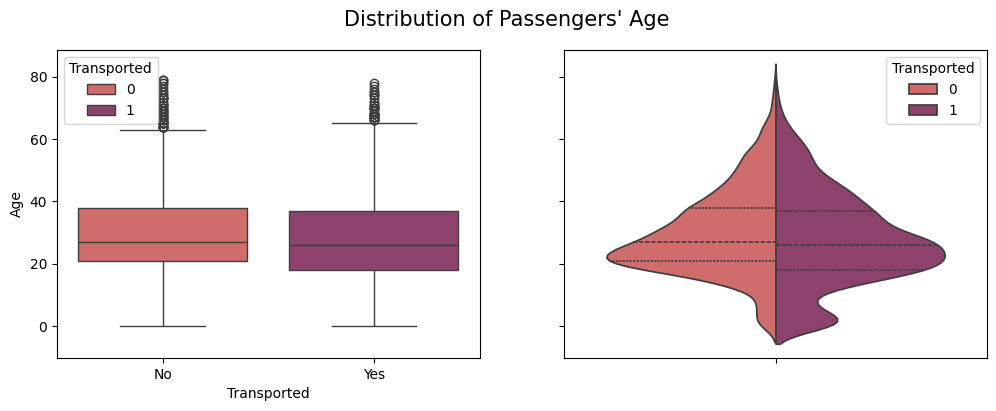

In [33]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

fig.suptitle("Distribution of Passengers' Age", fontsize=15)

ax1 = sns.boxplot(y=datac_enc.Age, x=datac_enc.Transported, hue=datac_enc.Transported, palette=palette, ax=axs[0])
ax2 = sns.violinplot(y=datac_enc.Age, hue=datac_enc.Transported, split=True, inner="quart", palette=palette, ax=axs[1])

ax1.set_xticks(ax1.get_xticks())
ax1.set_xticklabels(['No', 'Yes'])
ax1.set_ylabel('Age');

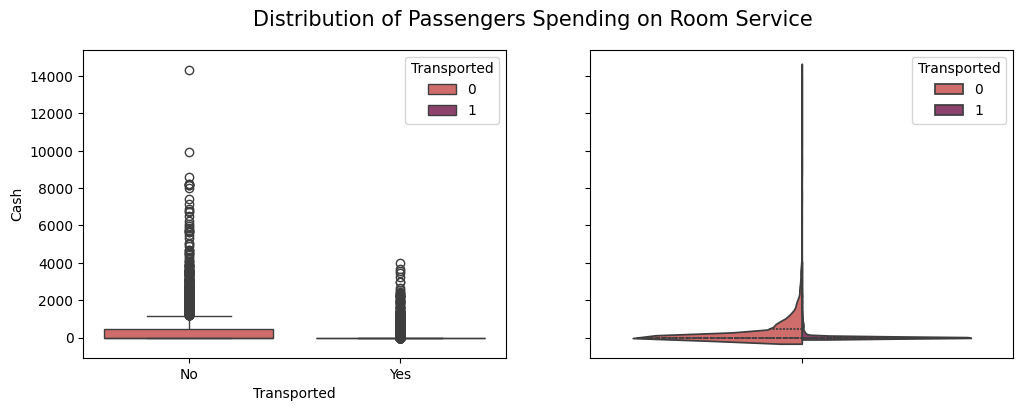

In [34]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

fig.suptitle("Distribution of Passengers Spending on Room Service", fontsize=15)

ax1 = sns.boxplot(
    y=datac_enc.RoomService, x=datac_enc.Transported, hue=datac_enc.Transported, palette=palette, ax=axs[0]
)
ax2 = sns.violinplot(
    y=datac_enc.RoomService, hue=datac_enc.Transported, split=True, inner="quart", palette=palette, ax=axs[1]
)

ax1.set_xticks(ax1.get_xticks())
ax1.set_xticklabels(['No', 'Yes'])
ax1.set_ylabel('Cash');

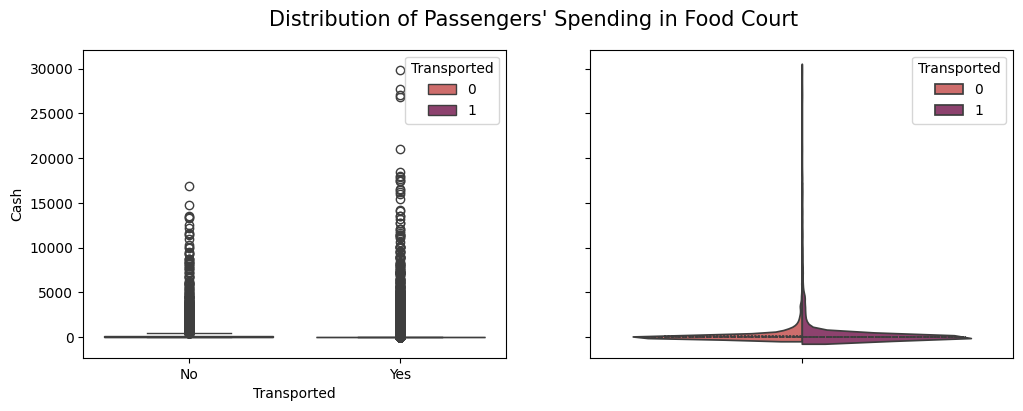

In [35]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

fig.suptitle("Distribution of Passengers' Spending in Food Court", fontsize=15)

ax1 = sns.boxplot(y=datac_enc.FoodCourt, x=datac_enc.Transported, hue=datac_enc.Transported, palette=palette, ax=axs[0])
ax2 = sns.violinplot(
    y=datac_enc.FoodCourt, hue=datac_enc.Transported, split=True, inner="quart", palette=palette, ax=axs[1]
)

ax1.set_xticks(ax1.get_xticks())
ax1.set_xticklabels(['No', 'Yes'])
ax1.set_ylabel('Cash');

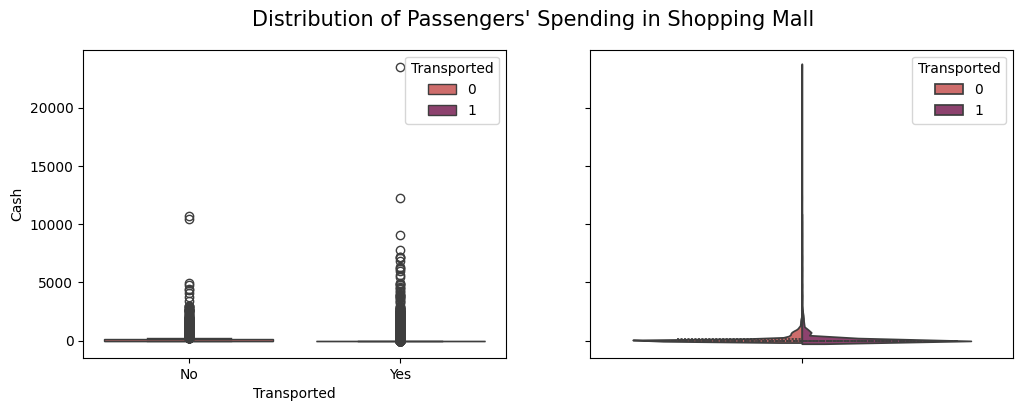

In [36]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

fig.suptitle("Distribution of Passengers' Spending in Shopping Mall", fontsize=15)

ax1 = sns.boxplot(
    y=datac_enc.ShoppingMall, x=datac_enc.Transported, hue=datac_enc.Transported, palette=palette, ax=axs[0]
)
ax2 = sns.violinplot(
    y=datac_enc.ShoppingMall, hue=datac_enc.Transported, split=True, inner="quart", palette=palette, ax=axs[1]
)

ax1.set_xticks(ax1.get_xticks())
ax1.set_xticklabels(['No', 'Yes'])
ax1.set_ylabel('Cash');

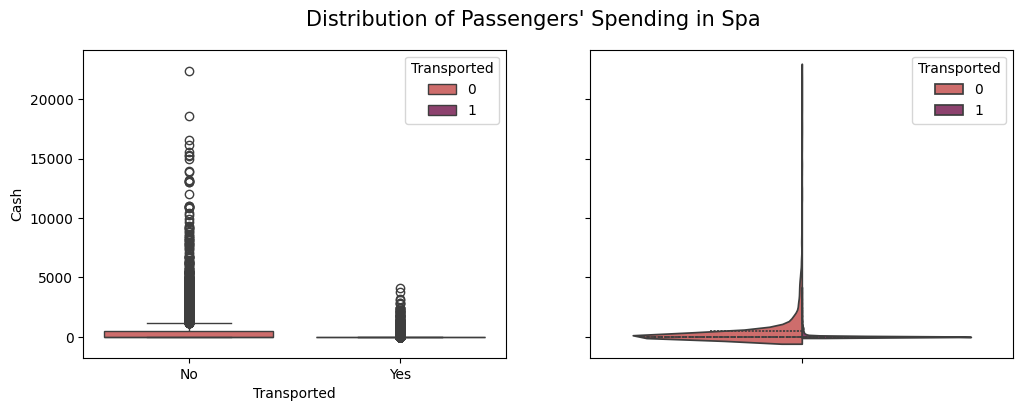

In [37]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

fig.suptitle("Distribution of Passengers' Spending in Spa", fontsize=15)

ax1 = sns.boxplot(y=datac_enc.Spa, x=datac_enc.Transported, hue=datac_enc.Transported, palette=palette, ax=axs[0])
ax2 = sns.violinplot(y=datac_enc.Spa, hue=datac_enc.Transported, split=True, inner="quart", palette=palette, ax=axs[1])

ax1.set_xticks(ax1.get_xticks())
ax1.set_xticklabels(['No', 'Yes'])
ax1.set_ylabel('Cash');

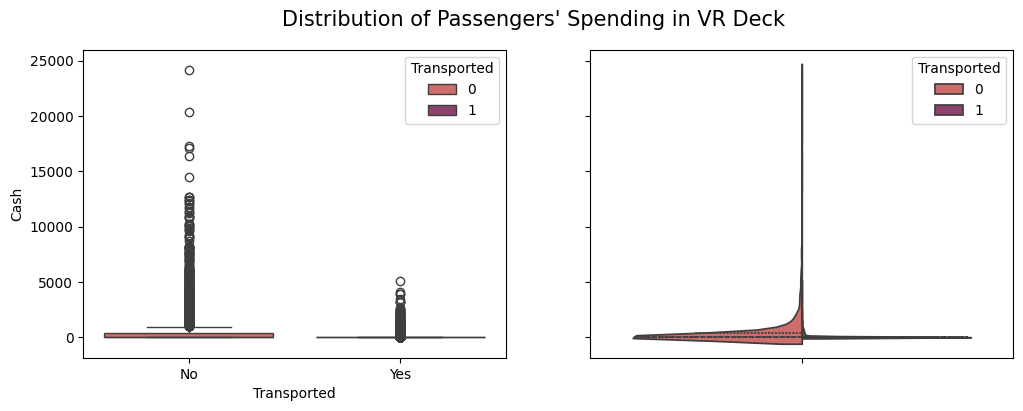

In [38]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

fig.suptitle("Distribution of Passengers' Spending in VR Deck", fontsize=15)

ax1 = sns.boxplot(y=datac_enc.VRDeck, x=datac_enc.Transported, hue=datac_enc.Transported, palette=palette, ax=axs[0])
ax2 = sns.violinplot(
    y=datac_enc.VRDeck, hue=datac_enc.Transported, split=True, inner="quart", palette=palette, ax=axs[1]
)

ax1.set_xticks(ax1.get_xticks())
ax1.set_xticklabels(['No', 'Yes'])
ax1.set_ylabel('Cash');

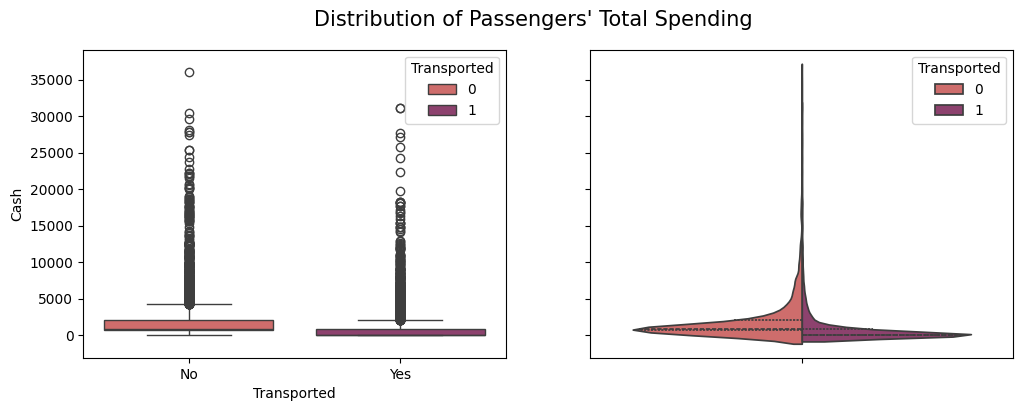

In [39]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

fig.suptitle("Distribution of Passengers' Total Spending", fontsize=15)

ax1 = sns.boxplot(y=datac_enc.total, x=datac_enc.Transported, hue=datac_enc.Transported, palette=palette, ax=axs[0])
ax2 = sns.violinplot(
    y=datac_enc.total, hue=datac_enc.Transported, split=True, inner="quart", palette=palette, ax=axs[1]
)

ax1.set_xticks(ax1.get_xticks())
ax1.set_xticklabels(['No', 'Yes'])
ax1.set_ylabel('Cash');

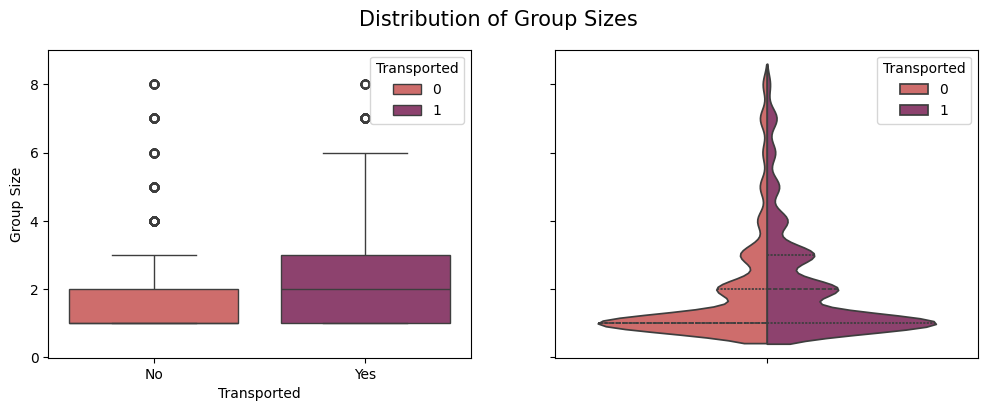

In [40]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

fig.suptitle("Distribution of Group Sizes", fontsize=15)

ax1 = sns.boxplot(
    y=datac_enc.group_size, x=datac_enc.Transported, hue=datac_enc.Transported, palette=palette, ax=axs[0]
)
ax2 = sns.violinplot(
    y=datac_enc.group_size, hue=datac_enc.Transported, split=True, inner="quart", palette=palette, ax=axs[1]
)

ax1.set_xticks(ax1.get_xticks())
ax1.set_xticklabels(['No', 'Yes'])
ax1.set_ylabel('Group Size');

Overall, age seems to be in reasonable limits. There are passengers, who would spend much more money the attractions, compared to others. Bigger group sizes are rarer.

All of the data points are valid therefore none of them were removed.

# Perform statistical inference

After exploring the data, we are going to compare passengers who were transported and who weren't, using hypothesis testing. All of the features will be tested, if they do influence chances to be transported or not. Hypothesis testing will be applied to check if there is any statistical significance.
$ H_0 $ will always be that there is no difference, and $ H_1 $ accordingly will be that there is a difference. Chosen significance level – $ α $ will be 5% (or 0.05). Since there are a lot of features Bonferroni Correction will be used: $ α $ is going to be divided by the number of hypotheses made.

The results will not determine whether or not the feature is going to be taken for modeling, however it will give important insights which of the features might be more important than others.

In [41]:
# Since there are only 5 instances of passengers in deck T it will not be tested.
binary_list.remove("deck_T")
total_tests = len(nonbinary_list) + len(binary_list)
alfa = 0.05 / total_tests
print(f'Due to Bonferroni Correction significance level will be {alfa}')

Due to Bonferroni Correction significance level will be 0.0016129032258064516


In [42]:
mask = datac_enc['Transported'] == 1

transported = datac_enc[mask]
not_transported = datac_enc[~mask]

assert len(transported) + len(not_transported) == len(datac_enc)

## Testing Non-Binary Numerical Features

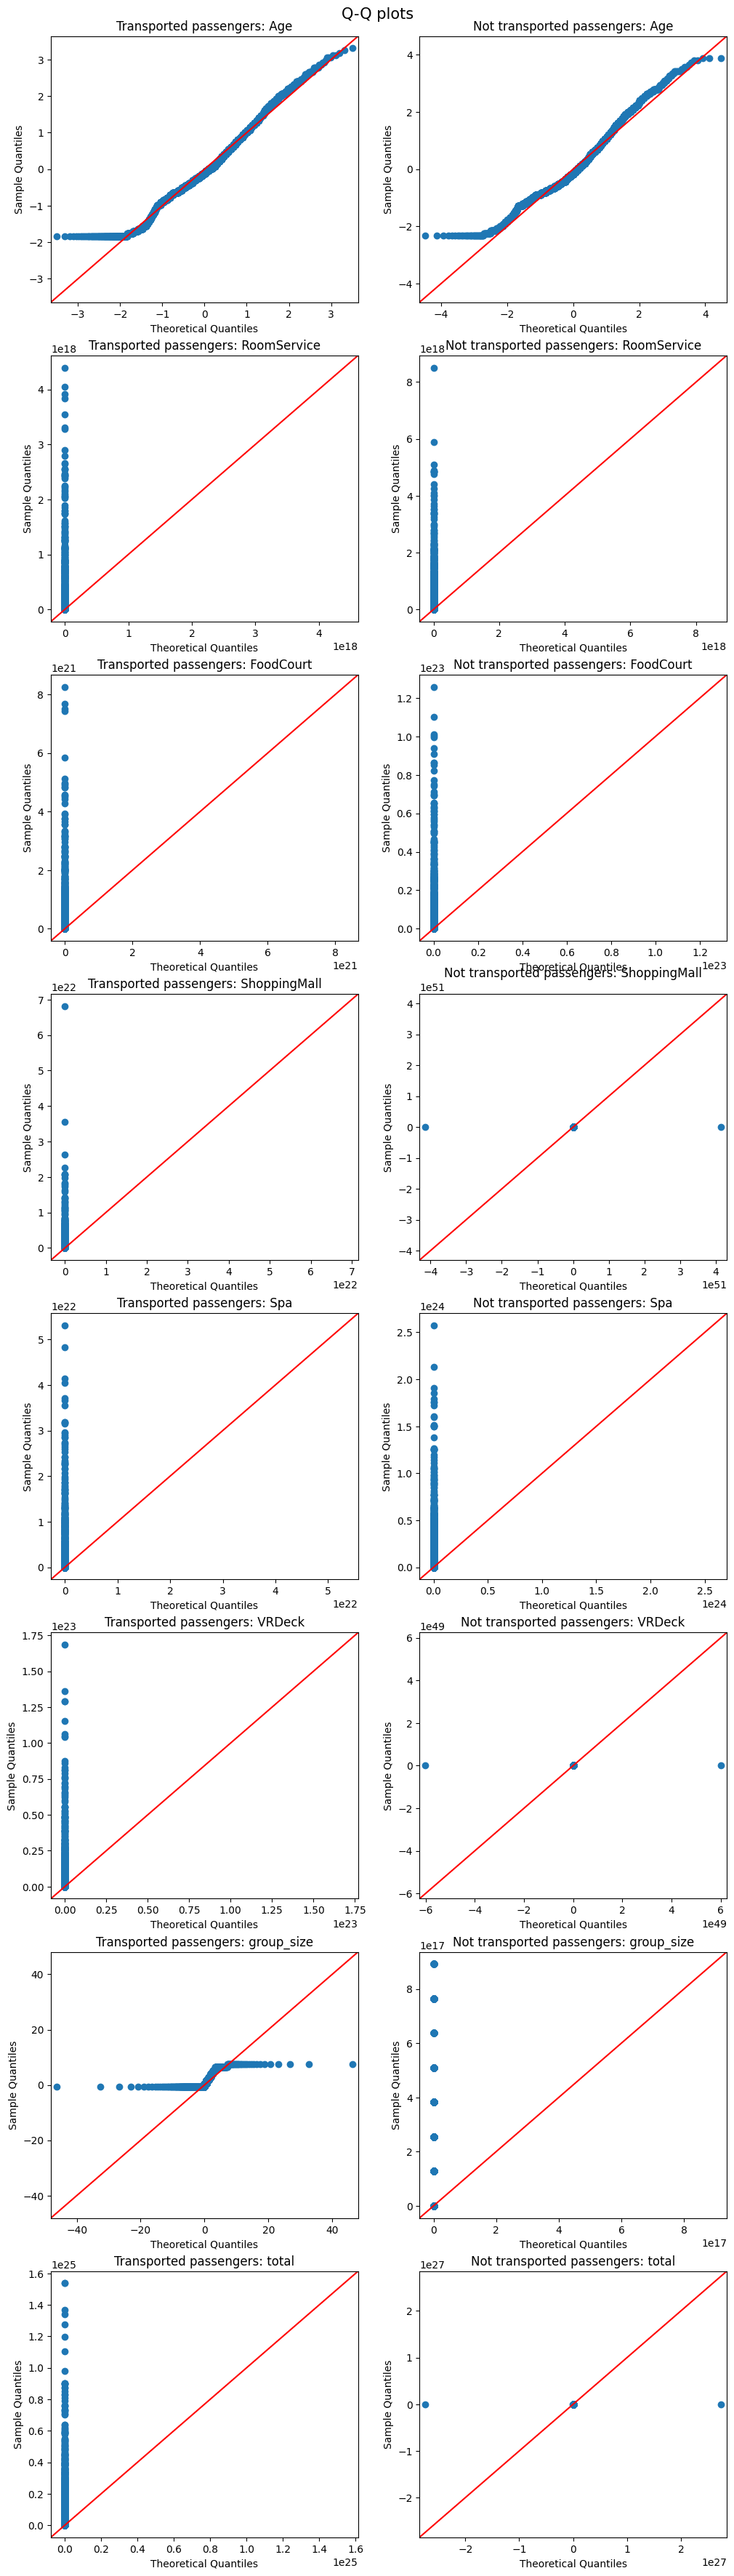

In [43]:
plot_rows = len(nonbinary_list)

fig, axs = plt.subplots(plot_rows, 2, figsize=(12, (5 * plot_rows)))

fig.suptitle('Q-Q plots', fontsize=15)
fig.subplots_adjust(top=0.97)

row = 0
for i in nonbinary_list:
    ax1 = sm.qqplot(transported[i].dropna(), stats.t, fit=True, line="45", ax=axs[row, 0])
    ax2 = sm.qqplot(not_transported[i].dropna(), stats.t, fit=True, line="45", ax=axs[row, 1])

    axs[row, 0].set_title(f'Transported passengers: {i}')
    axs[row, 1].set_title(f'Not transported passengers: {i}')
    row += 1

We can see that only passengers age is normally distributed, rest of collected features are not, as we can see from the Q-Q plots. In fact they are highly skewed, therefore for hypothesis testing I will also use Mann-Whitney U Test, which will be the main determining factor for all other attributes.

In [44]:
for i in nonbinary_list:
    print(f'🔹 Feature: {i}')
    hypothesis_tests_f(
        transported[i].dropna(),
        not_transported[i].dropna(),
        p=alfa,
        name_x='Transported passengers',
        name_y='Not transported passengers',
        test=['t', 'mw'],
    )
    print('--------------------------------------------------------------------')

🔹 Feature: Age
95% confidence intervals:

Transported passengers
(np.float64(27.29520073314416), np.float64(28.2024671773036))
Not transported passengers
(np.float64(29.509711157617865), np.float64(30.33600583244366))
Intervals do not overlap.

Set p value is 0.0016129032258064516.

TtestResult(statistic=np.float64(-6.941461666045089), pvalue=np.float64(4.165050977554493e-12), df=np.float64(8512.0))
t test results are statistically significant

MannwhitneyuResult(statistic=np.float64(8317627.0), pvalue=np.float64(5.619032220494119e-11))
Mann–Whitney U test results are statistically significant

--------------------------------------------------------------------
🔹 Feature: RoomService
95% confidence intervals:

Transported passengers
(np.float64(54.87700637656135), np.float64(71.31903553263538))
Not transported passengers
(np.float64(362.83007160396966), np.float64(415.7020602433151))
Intervals do not overlap.

Set p value is 0.0016129032258064516.

TtestResult(statistic=np.float64(-23

We can see that in almost every instance results are statistically significant for both Mann-Whitney U test and t test. The only exception is about spending money at shopping mall, where t test was not statistically significant and Mann-Whitney U test was. Because the data distribution far from normal, as we can see from Q-Q plots, Mann-Whitney U test will be the primary criteria for determining if the results are statistically significant or not. To sum up, all of the features were statistically important when it comes to transporting the passengers.

## Binary Data Chi-Squared Test

Is there a difference in frequency of transportation binary features?

Like before, $ H_0 $ will be that there is no difference. $ H_1 $ will be that there is a difference.

Chi-square test is going to be used to check if there is a statistical difference in binary features.

In [45]:
for i in binary_list:
    print(f'🔹 Feature: {i} \n')
    chi2_test_f(datac_enc, 'Transported', i, p=alfa)
    print('--------------------------------------------------------------------')

🔹 Feature: CryoSleep 

CryoSleep      No   Yes
Transported            
No           3650   554
Yes          1789  2483
Chi2ContingencyResult(statistic=np.float64(1859.6127129888841), pvalue=np.float64(0.0), dof=1, expected_freq=array([[2697.68239736, 1506.31760264],
       [2741.31760264, 1530.68239736]]))

Set p value is 0.0016129032258064516.
Results are statistically significant

--------------------------------------------------------------------
🔹 Feature: VIP 

VIP            No  Yes
Transported           
No           4093  123
Yes          4198   76
Chi2ContingencyResult(statistic=np.float64(11.542020738162797), pvalue=np.float64(0.0006804064556968345), dof=1, expected_freq=array([[4117.17974087,   98.82025913],
       [4173.82025913,  100.17974087]]))

Set p value is 0.0016129032258064516.
Results are statistically significant

--------------------------------------------------------------------
🔹 Feature: spent_money 

spent_money    No   Yes
Transported            
No       

In majority of cases the results are statistically significant. We have failed to show statistical difference for the passenger is more likely to be transported or not, if they are traveling from Mars, towards destination PSO J318.5-22, their cabins are in deck D, A or G. It is worth mentioning that for cabins in deck D, p value (0.00176) is close to our set significance level (0.00161).

# Modeling

Around half of the passengers were transported (50.36%). The goal for Kaggle submission is to have accuracy score of 0.79 or above.

First we split the data to X and y, then we write functions for preprocessing the data. 

For modeling simple model using logistic regression will be created. The goal is to create a model which performs better than it. Models will be evaluated according to accuracy.

For hyper parameter tuning randomized search firstly will be used, to get an idea what should be used. After it the model will be tuned using grid search.

In [46]:
X = data.drop(['Transported'], axis=1)
y = data['Transported'].astype(int)

## Functions for pipeline

In [47]:
# Column to split
columns_to_split = {'Cabin': ['deck', 'num', 'side'], 'PassengerId': ['group', 'number_in_group']}


def preprocess_data(df: pd.DataFrame) -> pd.DataFrame:
    '''
    A function made for the preprocessor pipeline to split the cabins' column,
    calculate total spending on attractions and obtain group size for each
    group. It also transforms few boolean type columns into type float.
    It needs pandas dataframe as an argument and returns the modified dataframe.
    '''

    df = df.copy()  # To avoid modifying the original DataFrame

    df['total'] = df[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].fillna(0).sum(axis=1)

    for col, new_cols in columns_to_split.items():
        df[new_cols] = df[col].str.split('/', expand=True) if col == 'Cabin' else df[col].str.split('_', expand=True)

    df['group_size'] = df.groupby('group')['number_in_group'].transform('max').astype(int)

    df['VIP'] = df['VIP'].astype(float)
    df['CryoSleep'] = df['CryoSleep'].astype(float)

    return df


def spent_or_not(df: pd.DataFrame) -> pd.DataFrame:
    '''
    This function is made for the preprocessor pipeline to add values if the
    passengers spend money or not, regardless on the amount they have used.
    It needs pandas dataframe as an argument and returns the modified dataframe.
    '''

    df['spent_money'] = df['total'].apply(lambda x: 1 if x > 0 else 0)
    df['spent_on_room_service'] = df['RoomService'].apply(lambda x: 1 if x > 0 else 0)
    df['spent_in_food_court'] = df['FoodCourt'].apply(lambda x: 1 if x > 0 else 0)
    df['spent_in_shopping_mall'] = df['ShoppingMall'].apply(lambda x: 1 if x > 0 else 0)
    df['spent_on_spa'] = df['Spa'].apply(lambda x: 1 if x > 0 else 0)
    df['spent_in_vr_deck'] = df['VRDeck'].apply(lambda x: 1 if x > 0 else 0)

    return df


# Specify columns to drop
columns_to_drop = ['PassengerId', 'Cabin', 'Name', 'num', 'group', 'number_in_group']

# in case i just want to leave if they spent money or not
columns_to_drop_spending = ['total', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']


def encoder_f(df: pd.DataFrame) -> pd.DataFrame:
    '''
    A function made to one-hot encode categorical features in the pipeline.
    It needs pandas dataframe as an argument and returns the modified dataframe.
    '''

    x_num = df.select_dtypes(exclude='object').reset_index(drop=True)
    x_cat = df.select_dtypes(include='object')

    encoder = OneHotEncoder(sparse_output=False)
    x_encoded = encoder.fit_transform(x_cat)

    # create the names for the one-hot encoded categorical features
    categorical_columns = [f'{col}_{cat}' for i, col in enumerate(x_cat.columns) for cat in encoder.categories_[i]]

    # put the features into a dataframe and join with the original
    # numerical features

    one_hot_features = pd.DataFrame(x_encoded, columns=categorical_columns)
    # deck_T will also be dropped as there were only 5 passengers on it
    one_hot_features = one_hot_features.drop(
        ['HomePlanet_nan', 'Destination_nan', 'deck_nan', 'side_nan', 'deck_T'], axis=1
    )
    df = x_num.join(one_hot_features)

    return df


imputer = SimpleImputer(strategy='most_frequent')

# Create a pipeline
preprocessor = make_pipeline(
    FunctionTransformer(preprocess_data, validate=False),
    FunctionTransformer(spent_or_not, validate=False),
    FunctionTransformer(lambda df: df.drop(columns_to_drop, axis=1)),
    FunctionTransformer(encoder_f, validate=False),
)

pipeline = Pipeline([('preprocessing', preprocessor)])

# Transform the DataFrame using the pipeline
transformed_data = pipeline.fit_transform(X)
transformed_data.T

,0,1,2,3,4,5,6,7,8,9,...,8683,8684,8685,8686,8687,8688,8689,8690,8691,8692
CryoSleep,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,NaN,0.0,1.0,0.0,0.0,0.0
Age,39.0,24.0,58.0,33.0,16.0,44.0,26.0,28.0,35.0,14.0,...,21.0,23.0,0.0,32.0,30.0,41.0,18.0,26.0,32.0,44.0
VIP,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
RoomService,0.0,109.0,43.0,0.0,303.0,0.0,42.0,0.0,0.0,0.0,...,86.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,126.0
FoodCourt,0.0,9.0,3576.0,1283.0,70.0,483.0,1539.0,0.0,785.0,0.0,...,3.0,0.0,0.0,1146.0,3208.0,6819.0,0.0,0.0,1049.0,4688.0
ShoppingMall,0.0,25.0,0.0,371.0,151.0,0.0,3.0,0.0,17.0,0.0,...,149.0,0.0,0.0,0.0,0.0,0.0,0.0,1872.0,0.0,0.0
Spa,0.0,549.0,6715.0,3329.0,565.0,291.0,0.0,0.0,216.0,0.0,...,208.0,0.0,0.0,50.0,2.0,1643.0,0.0,1.0,353.0,0.0
VRDeck,0.0,44.0,49.0,193.0,2.0,0.0,0.0,NaN,0.0,0.0,...,329.0,0.0,0.0,34.0,330.0,74.0,0.0,0.0,3235.0,12.0
total,0.0,736.0,10383.0,5176.0,1091.0,774.0,1584.0,0.0,1018.0,0.0,...,775.0,0.0,0.0,1231.0,3540.0,8536.0,0.0,1873.0,4637.0,4826.0
group_size,1.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,3.0,...,2.0,1.0,3.0,3.0,3.0,1.0,1.0,1.0,2.0,2.0


## Simple baseline model

In [48]:
# Suppress convergence warnings
warnings.simplefilter("ignore", ConvergenceWarning)

preprocessor = make_pipeline(
    FunctionTransformer(preprocess_data, validate=False),
    FunctionTransformer(lambda df: df.drop(columns_to_drop, axis=1)),
    FunctionTransformer(encoder_f, validate=False),
)

transformed_X = preprocessor.fit_transform(X)

model = Pipeline([('imput', imputer), ("clf", LogisticRegression(random_state=0))])

tol = [0.0001, 0.0002, 0.001]
max_iter = [1000, 200, 500]
C = [10, 1.0, 0.1, 0.01]

param_grid = dict(clf__tol=tol, clf__max_iter=max_iter, clf__C=C)

best_log = grid_search_f(model, param_grid, transformed_X, y, scoring='accuracy', showall=False)

Scoring: accuracy
🔹 Top 3 Results with Evaluation Metrics::
1. Mean: 0.790752 ± 0.007714 | Params: {'clf__C': 0.01, 'clf__max_iter': 200, 'clf__tol': 0.0001}
   - Precision: 0.7933 | Recall: 0.7908 | F1-score: 0.7902 | Accuracy: 0.7908
 
2. Mean: 0.790752 ± 0.007714 | Params: {'clf__C': 0.01, 'clf__max_iter': 200, 'clf__tol': 0.0002}
   - Precision: 0.7933 | Recall: 0.7908 | F1-score: 0.7902 | Accuracy: 0.7908
 
3. Mean: 0.790752 ± 0.007714 | Params: {'clf__C': 0.01, 'clf__max_iter': 200, 'clf__tol': 0.001}
   - Precision: 0.7933 | Recall: 0.7908 | F1-score: 0.7902 | Accuracy: 0.7908
 


In [49]:
%%time

x_train, x_val, y_train, y_val = train_test_split(
    transformed_X, y, test_size=0.2, random_state=0, stratify=data["Transported"]
)

log_model = Pipeline([('imput', imputer), ("clf", LogisticRegression(random_state=0))])
log_model.set_params(**best_log)
log_model.fit(x_train, y_train)
yhat = log_model.predict(x_train)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_train, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_train, prediction))

Confusion Matrix : 
 [[2549  903]
 [ 521 2981]]
              precision    recall  f1-score   support

           0       0.83      0.74      0.78      3452
           1       0.77      0.85      0.81      3502

    accuracy                           0.80      6954
   macro avg       0.80      0.79      0.79      6954
weighted avg       0.80      0.80      0.79      6954

CPU times: total: 141 ms
Wall time: 144 ms


Baseline logistic model has accuracy score above set target for Kaggle submission (0.79). The goal is to make model with higher accuracy score than this model.

## Random Forest

For random forest model, three different preprocessing strategies will be used. 

In all models: missing values will be filled with the most common value; columns 'PassengerId', 'Cabin', 'Name', 'num', 'group', 'number_in_group', 'deck_T' will be dropped; extracted features from Cabin column (deck and side), total group size; categorical features will be one hot encoded.

For the first model, all of the extracted features will be used: in addition to present features, total passengers' spending, and if a passenger spent money or not at attractions.
For second model there will be only total spending added.
For the third model, columns 'total', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck' will be dropped and instead only information if the passenger has spend money or not on the attractions used.

In the beginning the models' hyper parameters will be tuned using randomized search. Afterwards grid search will be used for final model selection.

### Model 1

In [50]:
preprocessor = make_pipeline(
    FunctionTransformer(preprocess_data, validate=False),
    FunctionTransformer(spent_or_not, validate=False),
    FunctionTransformer(lambda df: df.drop(columns_to_drop, axis=1)),
    FunctionTransformer(encoder_f, validate=False),
)

transformed_X = preprocessor.fit_transform(X)

#### Random search

In [51]:
# First run
model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])

n_estimators = [100]
max_depth = [10, 20, 30, 50, None]
min_samples_split = [2, 5, 10]
min_samples_leaf = [1, 2, 5]

param_dist = dict(
    clf__n_estimators=n_estimators,
    clf__max_depth=max_depth,
    clf__min_samples_split=min_samples_split,
    clf__min_samples_leaf=min_samples_leaf,
)

best_model_rf1 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.798921 ± 0.011553 | Params: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_depth': 10}
   - Precision: 0.7989 | Recall: 0.7989 | F1-score: 0.7989 | Accuracy: 0.7989
 
2. Mean: 0.797081 ± 0.012374 | Params: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 5, 'clf__max_depth': 30}
   - Precision: 0.7971 | Recall: 0.7971 | F1-score: 0.7971 | Accuracy: 0.7971
 
3. Mean: 0.791789 ± 0.010942 | Params: {'clf__n_estimators': 100, 'clf__min_samples_split': 10, 'clf__min_samples_leaf': 1, 'clf__max_depth': None}
   - Precision: 0.7924 | Recall: 0.7918 | F1-score: 0.7917 | Accuracy: 0.7918
 

🔸 **All Results:**
0.789603 (0.009875) with: {'clf__n_estimators': 100, 'clf__min_samples_split': 2, 'clf__min_samples_leaf': 2, 'clf__max_depth': 50}
0.786036 (0.005930) with: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 1, 

In [52]:
# Second run
model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])

n_estimators = [50, 100, 200]
max_depth = [10, 20]
min_samples_split = [5, 10, 15]
min_samples_leaf = [2, 3, 5]

param_dist = dict(
    clf__n_estimators=n_estimators,
    clf__max_depth=max_depth,
    clf__min_samples_split=min_samples_split,
    clf__min_samples_leaf=min_samples_leaf,
)

best_model_rf1 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.800072 ± 0.013509 | Params: {'clf__n_estimators': 200, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 3, 'clf__max_depth': 10}
   - Precision: 0.8001 | Recall: 0.8001 | F1-score: 0.8001 | Accuracy: 0.8001
 
2. Mean: 0.798806 ± 0.011032 | Params: {'clf__n_estimators': 200, 'clf__min_samples_split': 15, 'clf__min_samples_leaf': 5, 'clf__max_depth': 10}
   - Precision: 0.7989 | Recall: 0.7988 | F1-score: 0.7988 | Accuracy: 0.7988
 
3. Mean: 0.798691 ± 0.011486 | Params: {'clf__n_estimators': 200, 'clf__min_samples_split': 15, 'clf__min_samples_leaf': 5, 'clf__max_depth': 20}
   - Precision: 0.7987 | Recall: 0.7987 | F1-score: 0.7987 | Accuracy: 0.7987
 

🔸 **All Results:**
0.798691 (0.011486) with: {'clf__n_estimators': 200, 'clf__min_samples_split': 15, 'clf__min_samples_leaf': 5, 'clf__max_depth': 20}
0.795470 (0.011641) with: {'clf__n_estimators': 50, 'clf__min_samples_split': 15, 'clf__min_samples_leaf': 2, 

In [53]:
# Third run
model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])

n_estimators = [100, 200, 300, 400]
max_depth = [10]
min_samples_split = [8, 10, 12]
min_samples_leaf = [3, 5]
max_features = ['sqrt', 'log2', None]

param_dist = dict(
    clf__n_estimators=n_estimators,
    clf__max_depth=max_depth,
    clf__min_samples_split=min_samples_split,
    clf__min_samples_leaf=min_samples_leaf,
    clf__max_features=max_features,
)

best_model_rf1 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.799841 ± 0.009984 | Params: {'clf__n_estimators': 400, 'clf__min_samples_split': 10, 'clf__min_samples_leaf': 3, 'clf__max_features': 'sqrt', 'clf__max_depth': 10}
   - Precision: 0.7999 | Recall: 0.7998 | F1-score: 0.7998 | Accuracy: 0.7998
 
2. Mean: 0.798806 ± 0.012481 | Params: {'clf__n_estimators': 400, 'clf__min_samples_split': 8, 'clf__min_samples_leaf': 3, 'clf__max_features': None, 'clf__max_depth': 10}
   - Precision: 0.7988 | Recall: 0.7988 | F1-score: 0.7988 | Accuracy: 0.7988
 
3. Mean: 0.798576 ± 0.009824 | Params: {'clf__n_estimators': 300, 'clf__min_samples_split': 12, 'clf__min_samples_leaf': 5, 'clf__max_features': 'sqrt', 'clf__max_depth': 10}
   - Precision: 0.7986 | Recall: 0.7986 | F1-score: 0.7985 | Accuracy: 0.7986
 

🔸 **All Results:**
0.795470 (0.010241) with: {'clf__n_estimators': 300, 'clf__min_samples_split': 8, 'clf__min_samples_leaf': 3, 'clf__max_features': 'log2', 'clf__max_depth': 1

In [54]:
# Fourth run
model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])

n_estimators = [100, 200, 400, 500]
max_depth = [10]
min_samples_split = [10]
min_samples_leaf = [3, 5]
criterion = ['gini', 'entropy', 'log_loss']

param_dist = dict(
    clf__n_estimators=n_estimators,
    clf__max_depth=max_depth,
    clf__min_samples_split=min_samples_split,
    clf__min_samples_leaf=min_samples_leaf,
    clf__max_features=max_features,
    clf__criterion=criterion,
)

best_model_rf1 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.800531 ± 0.010874 | Params: {'clf__n_estimators': 400, 'clf__min_samples_split': 10, 'clf__min_samples_leaf': 3, 'clf__max_features': 'sqrt', 'clf__max_depth': 10, 'clf__criterion': 'entropy'}
   - Precision: 0.8006 | Recall: 0.8005 | F1-score: 0.8005 | Accuracy: 0.8005
 
2. Mean: 0.800301 ± 0.010060 | Params: {'clf__n_estimators': 500, 'clf__min_samples_split': 10, 'clf__min_samples_leaf': 3, 'clf__max_features': 'sqrt', 'clf__max_depth': 10, 'clf__criterion': 'entropy'}
   - Precision: 0.8003 | Recall: 0.8003 | F1-score: 0.8003 | Accuracy: 0.8003
 
3. Mean: 0.800301 ± 0.010060 | Params: {'clf__n_estimators': 500, 'clf__min_samples_split': 10, 'clf__min_samples_leaf': 3, 'clf__max_features': 'sqrt', 'clf__max_depth': 10, 'clf__criterion': 'log_loss'}
   - Precision: 0.8003 | Recall: 0.8003 | F1-score: 0.8003 | Accuracy: 0.8003
 

🔸 **All Results:**
0.800531 (0.010874) with: {'clf__n_estimators': 400, 'clf__min_samp

#### Final selection

In [55]:
# Final run
model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])

n_estimators = [400, 425, 450, 500]
max_depth = [10]
min_samples_split = [10]
min_samples_leaf = [3]
criterion = ['entropy', 'log_loss']

param_dist = dict(
    clf__n_estimators=n_estimators,
    clf__max_depth=max_depth,
    clf__min_samples_split=min_samples_split,
    clf__min_samples_leaf=min_samples_leaf,
    clf__criterion=criterion,
)

best_model_rf1 = grid_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=False)

Scoring: accuracy
🔹 Top 3 Results with Evaluation Metrics::
1. Mean: 0.801337 ± 0.010363 | Params: {'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_leaf': 3, 'clf__min_samples_split': 10, 'clf__n_estimators': 425}
   - Precision: 0.8014 | Recall: 0.8013 | F1-score: 0.8013 | Accuracy: 0.8013
 
2. Mean: 0.801337 ± 0.010363 | Params: {'clf__criterion': 'log_loss', 'clf__max_depth': 10, 'clf__min_samples_leaf': 3, 'clf__min_samples_split': 10, 'clf__n_estimators': 425}
   - Precision: 0.8014 | Recall: 0.8013 | F1-score: 0.8013 | Accuracy: 0.8013
 
3. Mean: 0.800877 ± 0.010508 | Params: {'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_leaf': 3, 'clf__min_samples_split': 10, 'clf__n_estimators': 450}
   - Precision: 0.8009 | Recall: 0.8009 | F1-score: 0.8009 | Accuracy: 0.8009
 


In [56]:
%%time

x_train, x_val, y_train, y_val = train_test_split(
    transformed_X, y, test_size=0.2, random_state=0, stratify=data["Transported"]
)

forest_model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])
forest_model.set_params(**best_model_rf1)
forest_model.fit(x_train, y_train)
yhat = forest_model.predict(x_train)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_train, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_train, prediction))

Confusion Matrix : 
 [[2872  580]
 [ 493 3009]]
              precision    recall  f1-score   support

           0       0.85      0.83      0.84      3452
           1       0.84      0.86      0.85      3502

    accuracy                           0.85      6954
   macro avg       0.85      0.85      0.85      6954
weighted avg       0.85      0.85      0.85      6954

CPU times: total: 2.72 s
Wall time: 2.73 s


### Model 2

In [57]:
preprocessor = make_pipeline(
    FunctionTransformer(preprocess_data, validate=False),
    FunctionTransformer(lambda df: df.drop(columns_to_drop, axis=1)),
    FunctionTransformer(encoder_f, validate=False),
)

transformed_X = preprocessor.fit_transform(X)

#### Random search

In [58]:
# First run
model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])

n_estimators = [100]
max_depth = [10, 20, 30, 50, None]
min_samples_split = [2, 5, 10]
min_samples_leaf = [1, 2, 5]

param_dist = dict(
    clf__n_estimators=n_estimators,
    clf__max_depth=max_depth,
    clf__min_samples_split=min_samples_split,
    clf__min_samples_leaf=min_samples_leaf,
)

best_model_rf2 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.799956 ± 0.012251 | Params: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_depth': 10}
   - Precision: 0.8000 | Recall: 0.8000 | F1-score: 0.7999 | Accuracy: 0.8000
 
2. Mean: 0.797540 ± 0.012877 | Params: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 5, 'clf__max_depth': 30}
   - Precision: 0.7975 | Recall: 0.7975 | F1-score: 0.7975 | Accuracy: 0.7975
 
3. Mean: 0.793170 ± 0.012287 | Params: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_depth': 50}
   - Precision: 0.7936 | Recall: 0.7932 | F1-score: 0.7931 | Accuracy: 0.7932
 

🔸 **All Results:**
0.790754 (0.013282) with: {'clf__n_estimators': 100, 'clf__min_samples_split': 2, 'clf__min_samples_leaf': 2, 'clf__max_depth': 50}
0.788336 (0.008024) with: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 1, 'cl

In [59]:
# Second run
model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])

n_estimators = [50, 100, 200, 300]
max_depth = [10, 20, 30]
min_samples_split = [5]
min_samples_leaf = [2, 5]

param_dist = dict(
    clf__n_estimators=n_estimators,
    clf__max_depth=max_depth,
    clf__min_samples_split=min_samples_split,
    clf__min_samples_leaf=min_samples_leaf,
)

best_model_rf2 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.799956 ± 0.012251 | Params: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_depth': 10}
   - Precision: 0.8000 | Recall: 0.8000 | F1-score: 0.7999 | Accuracy: 0.8000
 
2. Mean: 0.799496 ± 0.014012 | Params: {'clf__n_estimators': 300, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 5, 'clf__max_depth': 30}
   - Precision: 0.7995 | Recall: 0.7995 | F1-score: 0.7995 | Accuracy: 0.7995
 
3. Mean: 0.798116 ± 0.013377 | Params: {'clf__n_estimators': 200, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 5, 'clf__max_depth': 30}
   - Precision: 0.7981 | Recall: 0.7981 | F1-score: 0.7981 | Accuracy: 0.7981
 

🔸 **All Results:**
0.793744 (0.010880) with: {'clf__n_estimators': 300, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_depth': 20}
0.792709 (0.012919) with: {'clf__n_estimators': 200, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'cl

In [60]:
# Third run
model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])

n_estimators = [100, 200, 300]
max_depth = [10, 30]
min_samples_split = [5]
min_samples_leaf = [2, 5]
max_features = ['sqrt', 'log2', None]
bootstrap = [True, False]

param_dist = dict(
    clf__n_estimators=n_estimators,
    clf__max_depth=max_depth,
    clf__min_samples_split=min_samples_split,
    clf__min_samples_leaf=min_samples_leaf,
    clf__max_features=max_features,
    clf__bootstrap=bootstrap,
)

best_model_rf2 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.799152 ± 0.013838 | Params: {'clf__n_estimators': 200, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_features': 'log2', 'clf__max_depth': 10, 'clf__bootstrap': True}
   - Precision: 0.7991 | Recall: 0.7991 | F1-score: 0.7991 | Accuracy: 0.7991
 
2. Mean: 0.798116 ± 0.013377 | Params: {'clf__n_estimators': 200, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 5, 'clf__max_features': 'sqrt', 'clf__max_depth': 30, 'clf__bootstrap': True}
   - Precision: 0.7981 | Recall: 0.7981 | F1-score: 0.7981 | Accuracy: 0.7981
 
3. Mean: 0.797196 ± 0.011149 | Params: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 5, 'clf__max_features': 'log2', 'clf__max_depth': 30, 'clf__bootstrap': True}
   - Precision: 0.7972 | Recall: 0.7972 | F1-score: 0.7972 | Accuracy: 0.7972
 

🔸 **All Results:**
0.793169 (0.012240) with: {'clf__n_estimators': 300, 'clf__min_samples_split': 5, 'clf

In [61]:
# Fourth run
model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])

n_estimators = [100, 150, 200, 250]
max_depth = [10]
min_samples_split = [5]
min_samples_leaf = [2]
max_features = ['sqrt', 'log2']
criterion = ['gini', 'entropy', 'log_loss']

param_dist = dict(
    clf__n_estimators=n_estimators,
    clf__max_depth=max_depth,
    clf__min_samples_split=min_samples_split,
    clf__min_samples_leaf=min_samples_leaf,
    clf__max_features=max_features,
    clf__criterion=criterion,
)

best_model_rf2 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.800417 ± 0.012107 | Params: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_features': 'sqrt', 'clf__max_depth': 10, 'clf__criterion': 'log_loss'}
   - Precision: 0.8004 | Recall: 0.8004 | F1-score: 0.8004 | Accuracy: 0.8004
 
2. Mean: 0.800417 ± 0.012107 | Params: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_features': 'sqrt', 'clf__max_depth': 10, 'clf__criterion': 'entropy'}
   - Precision: 0.8004 | Recall: 0.8004 | F1-score: 0.8004 | Accuracy: 0.8004
 
3. Mean: 0.799612 ± 0.013457 | Params: {'clf__n_estimators': 150, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_features': 'log2', 'clf__max_depth': 10, 'clf__criterion': 'entropy'}
   - Precision: 0.7996 | Recall: 0.7996 | F1-score: 0.7996 | Accuracy: 0.7996
 

🔸 **All Results:**
0.799381 (0.011518) with: {'clf__n_estimators': 250, 'clf__min_samples

#### Final selection

In [62]:
# Final run
model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])

n_estimators = [90, 100, 125, 150, 250, 400]
max_depth = [10]
min_samples_split = [5]
min_samples_leaf = [2]
criterion = ['entropy', 'log_loss']

param_dist = dict(
    clf__n_estimators=n_estimators,
    clf__max_depth=max_depth,
    clf__min_samples_split=min_samples_split,
    clf__min_samples_leaf=min_samples_leaf,
    clf__criterion=criterion,
)

best_model_rf2 = grid_search_f(model, param_dist, transformed_X, y, scoring='accuracy')

Scoring: accuracy
🔹 Top 3 Results with Evaluation Metrics::
1. Mean: 0.800417 ± 0.012107 | Params: {'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 5, 'clf__n_estimators': 100}
   - Precision: 0.8004 | Recall: 0.8004 | F1-score: 0.8004 | Accuracy: 0.8004
 
2. Mean: 0.800417 ± 0.012107 | Params: {'clf__criterion': 'log_loss', 'clf__max_depth': 10, 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 5, 'clf__n_estimators': 100}
   - Precision: 0.8004 | Recall: 0.8004 | F1-score: 0.8004 | Accuracy: 0.8004
 
3. Mean: 0.799726 ± 0.010361 | Params: {'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 5, 'clf__n_estimators': 90}
   - Precision: 0.7997 | Recall: 0.7997 | F1-score: 0.7997 | Accuracy: 0.7997
 


In [63]:
%%time

x_train, x_val, y_train, y_val = train_test_split(
    transformed_X, y, test_size=0.2, random_state=0, stratify=data["Transported"]
)

forest_model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])
forest_model.set_params(**best_model_rf2)
forest_model.fit(x_train, y_train)
yhat = forest_model.predict(x_train)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_train, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_train, prediction))

Confusion Matrix : 
 [[2887  565]
 [ 484 3018]]
              precision    recall  f1-score   support

           0       0.86      0.84      0.85      3452
           1       0.84      0.86      0.85      3502

    accuracy                           0.85      6954
   macro avg       0.85      0.85      0.85      6954
weighted avg       0.85      0.85      0.85      6954

CPU times: total: 766 ms
Wall time: 761 ms


### Model 3

In [64]:
preprocessor = make_pipeline(
    FunctionTransformer(preprocess_data, validate=False),
    FunctionTransformer(spent_or_not, validate=False),
    FunctionTransformer(lambda df: df.drop(columns_to_drop, axis=1)),
    FunctionTransformer(lambda df: df.drop(columns_to_drop_spending, axis=1)),
    FunctionTransformer(encoder_f, validate=False),
)

transformed_X = preprocessor.fit_transform(X)

#### Random search

In [65]:
# First run
model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])

n_estimators = [100]
max_depth = [10, 20, 30, 50, None]
min_samples_split = [2, 5, 10]
min_samples_leaf = [1, 2, 5]

param_dist = dict(
    clf__n_estimators=n_estimators,
    clf__max_depth=max_depth,
    clf__min_samples_split=min_samples_split,
    clf__min_samples_leaf=min_samples_leaf,
)

best_model_rf3 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.748766 ± 0.011802 | Params: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_depth': 10}
   - Precision: 0.7545 | Recall: 0.7488 | F1-score: 0.7475 | Accuracy: 0.7488
 
2. Mean: 0.748651 ± 0.012149 | Params: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 5, 'clf__max_depth': 30}
   - Precision: 0.7544 | Recall: 0.7486 | F1-score: 0.7474 | Accuracy: 0.7486
 
3. Mean: 0.736573 ± 0.011851 | Params: {'clf__n_estimators': 100, 'clf__min_samples_split': 10, 'clf__min_samples_leaf': 1, 'clf__max_depth': 20}
   - Precision: 0.7424 | Recall: 0.7366 | F1-score: 0.7352 | Accuracy: 0.7366
 

🔸 **All Results:**
0.730244 (0.008570) with: {'clf__n_estimators': 100, 'clf__min_samples_split': 2, 'clf__min_samples_leaf': 2, 'clf__max_depth': 50}
0.717936 (0.007447) with: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 1, 'c

In [66]:
# Second run
model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])

n_estimators = [50, 100, 200, 400]
max_depth = [10, 20, 30]
min_samples_split = [5, 10, 15]
min_samples_leaf = [2, 5]

param_dist = dict(
    clf__n_estimators=n_estimators,
    clf__max_depth=max_depth,
    clf__min_samples_split=min_samples_split,
    clf__min_samples_leaf=min_samples_leaf,
)

best_model_rf3 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.751297 ± 0.012549 | Params: {'clf__n_estimators': 200, 'clf__min_samples_split': 15, 'clf__min_samples_leaf': 5, 'clf__max_depth': 10}
   - Precision: 0.7568 | Recall: 0.7513 | F1-score: 0.7501 | Accuracy: 0.7513
 
2. Mean: 0.750721 ± 0.012784 | Params: {'clf__n_estimators': 400, 'clf__min_samples_split': 15, 'clf__min_samples_leaf': 5, 'clf__max_depth': 30}
   - Precision: 0.7568 | Recall: 0.7507 | F1-score: 0.7494 | Accuracy: 0.7507
 
3. Mean: 0.749686 ± 0.010625 | Params: {'clf__n_estimators': 400, 'clf__min_samples_split': 10, 'clf__min_samples_leaf': 2, 'clf__max_depth': 10}
   - Precision: 0.7556 | Recall: 0.7497 | F1-score: 0.7484 | Accuracy: 0.7497
 

🔸 **All Results:**
0.732661 (0.009595) with: {'clf__n_estimators': 200, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_depth': 20}
0.733350 (0.008066) with: {'clf__n_estimators': 400, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 

In [67]:
# Third run
model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])

n_estimators = [200, 300, 400]
max_depth = [10, 30]
min_samples_split = [15, 20]
min_samples_leaf = [2, 5]
max_features = ['sqrt', 'log2', None]
bootstrap = [True, False]

param_dist = dict(
    clf__n_estimators=n_estimators,
    clf__max_depth=max_depth,
    clf__min_samples_split=min_samples_split,
    clf__min_samples_leaf=min_samples_leaf,
    clf__max_features=max_features,
    clf__bootstrap=bootstrap,
)

best_model_rf3 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.751987 ± 0.012876 | Params: {'clf__n_estimators': 300, 'clf__min_samples_split': 15, 'clf__min_samples_leaf': 5, 'clf__max_features': 'sqrt', 'clf__max_depth': 10, 'clf__bootstrap': True}
   - Precision: 0.7572 | Recall: 0.7520 | F1-score: 0.7509 | Accuracy: 0.7520
 
2. Mean: 0.750607 ± 0.012644 | Params: {'clf__n_estimators': 300, 'clf__min_samples_split': 20, 'clf__min_samples_leaf': 2, 'clf__max_features': 'log2', 'clf__max_depth': 10, 'clf__bootstrap': True}
   - Precision: 0.7564 | Recall: 0.7506 | F1-score: 0.7494 | Accuracy: 0.7506
 
3. Mean: 0.750146 ± 0.011661 | Params: {'clf__n_estimators': 400, 'clf__min_samples_split': 20, 'clf__min_samples_leaf': 5, 'clf__max_features': 'log2', 'clf__max_depth': 30, 'clf__bootstrap': True}
   - Precision: 0.7566 | Recall: 0.7501 | F1-score: 0.7488 | Accuracy: 0.7501
 

🔸 **All Results:**
0.751987 (0.012876) with: {'clf__n_estimators': 300, 'clf__min_samples_split': 15, 

In [68]:
# Fourth run
model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])

n_estimators = [300, 350, 400, 450]
max_depth = [10]
min_samples_split = [15]
min_samples_leaf = [5]
max_features = ['sqrt', 'log2']
criterion = ['gini', 'entropy', 'log_loss']

param_dist = dict(
    clf__n_estimators=n_estimators,
    clf__max_depth=max_depth,
    clf__min_samples_split=min_samples_split,
    clf__min_samples_leaf=min_samples_leaf,
    clf__max_features=max_features,
    clf__criterion=criterion,
)

best_model_rf3 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.752792 ± 0.011809 | Params: {'clf__n_estimators': 400, 'clf__min_samples_split': 15, 'clf__min_samples_leaf': 5, 'clf__max_features': 'sqrt', 'clf__max_depth': 10, 'clf__criterion': 'entropy'}
   - Precision: 0.7578 | Recall: 0.7528 | F1-score: 0.7518 | Accuracy: 0.7528
 
2. Mean: 0.752102 ± 0.011108 | Params: {'clf__n_estimators': 300, 'clf__min_samples_split': 15, 'clf__min_samples_leaf': 5, 'clf__max_features': 'sqrt', 'clf__max_depth': 10, 'clf__criterion': 'log_loss'}
   - Precision: 0.7573 | Recall: 0.7521 | F1-score: 0.7510 | Accuracy: 0.7521
 
3. Mean: 0.752102 ± 0.011108 | Params: {'clf__n_estimators': 300, 'clf__min_samples_split': 15, 'clf__min_samples_leaf': 5, 'clf__max_features': 'sqrt', 'clf__max_depth': 10, 'clf__criterion': 'entropy'}
   - Precision: 0.7573 | Recall: 0.7521 | F1-score: 0.7510 | Accuracy: 0.7521
 

🔸 **All Results:**
0.751987 (0.010735) with: {'clf__n_estimators': 450, 'clf__min_samp

#### Final selection

In [69]:
# Final run
model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])

n_estimators = [300, 350, 400]
max_depth = [10]
min_samples_split = [15, 20]
min_samples_leaf = [5]
criterion = ['entropy', 'log_loss']

param_dist = dict(
    clf__n_estimators=n_estimators,
    clf__max_depth=max_depth,
    clf__min_samples_split=min_samples_split,
    clf__min_samples_leaf=min_samples_leaf,
    clf__criterion=criterion,
)

best_model_rf3 = grid_search_f(model, param_dist, transformed_X, y, scoring='accuracy')

Scoring: accuracy
🔹 Top 3 Results with Evaluation Metrics::
1. Mean: 0.753828 ± 0.012125 | Params: {'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_leaf': 5, 'clf__min_samples_split': 20, 'clf__n_estimators': 350}
   - Precision: 0.7589 | Recall: 0.7538 | F1-score: 0.7528 | Accuracy: 0.7538
 
2. Mean: 0.753828 ± 0.012125 | Params: {'clf__criterion': 'log_loss', 'clf__max_depth': 10, 'clf__min_samples_leaf': 5, 'clf__min_samples_split': 20, 'clf__n_estimators': 350}
   - Precision: 0.7589 | Recall: 0.7538 | F1-score: 0.7528 | Accuracy: 0.7538
 
3. Mean: 0.753712 ± 0.011520 | Params: {'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_leaf': 5, 'clf__min_samples_split': 20, 'clf__n_estimators': 400}
   - Precision: 0.7588 | Recall: 0.7537 | F1-score: 0.7527 | Accuracy: 0.7537
 


In [70]:
%%time

x_train, x_val, y_train, y_val = train_test_split(
    transformed_X, y, test_size=0.2, random_state=0, stratify=data["Transported"]
)

forest_model = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])
forest_model.set_params(**best_model_rf3)
forest_model.fit(x_train, y_train)
yhat = forest_model.predict(x_train)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_train, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_train, prediction))

Confusion Matrix : 
 [[2889  563]
 [1033 2469]]
              precision    recall  f1-score   support

           0       0.74      0.84      0.78      3452
           1       0.81      0.71      0.76      3502

    accuracy                           0.77      6954
   macro avg       0.78      0.77      0.77      6954
weighted avg       0.78      0.77      0.77      6954

CPU times: total: 1.42 s
Wall time: 1.43 s


### Summary

Three different data preprocessing strategies were used to select best random forest model. The first and second models had same the accuracy, however the second model is much faster. Both had accuracy of 0.85, surpassing the threshold of 0.8 by the logistic model. The third model only had information if the passenger spent money or not and not total amounts. It performed the worst out of three (accuracy 0.77). Therefore, having separate information, if overall the customer has spent money or not, does not increase the accuracy or performance of the model, and having it alone is not enough to pass set threshold.

## Support Vector Machine (SVM)

For support vector machine, two different preprocessing strategies will be used. They will be same as second and third in random forest model. The first one did not improve performance in the previous model and was slow, consequently, it is no use testing it.

Same as previously, in the beginning the models' hyper parameters will be tuned using randomized search. Afterwards grid search will be used for final model selection.

### Model 1

In [71]:
preprocessor = make_pipeline(
    FunctionTransformer(preprocess_data, validate=False),
    FunctionTransformer(lambda df: df.drop(columns_to_drop, axis=1)),
    FunctionTransformer(encoder_f, validate=False),
)

transformed_X = preprocessor.fit_transform(X)

#### Random search

In [72]:
# First run
model = Pipeline([('imput', imputer), ("clf", SVC(random_state=0))])

kernel = ['rbf']
C = [50, 10, 1.0, 0.1, 0.01]
gamma = ["scale", "auto", 0.001, 0.01, 0.1, 1]

param_dist = dict(
    clf__kernel=kernel,
    clf__C=C,
    clf__gamma=gamma,
)

best_model_svm1 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.740024 ± 0.011245 | Params: {'clf__kernel': 'rbf', 'clf__gamma': 'auto', 'clf__C': 1.0}
   - Precision: 0.7494 | Recall: 0.7400 | F1-score: 0.7378 | Accuracy: 0.7400
 
2. Mean: 0.739909 ± 0.012138 | Params: {'clf__kernel': 'rbf', 'clf__gamma': 0.001, 'clf__C': 50}
   - Precision: 0.7423 | Recall: 0.7399 | F1-score: 0.7394 | Accuracy: 0.7399
 
3. Mean: 0.736803 ± 0.012744 | Params: {'clf__kernel': 'rbf', 'clf__gamma': 0.001, 'clf__C': 0.01}
   - Precision: 0.7437 | Recall: 0.7368 | F1-score: 0.7352 | Accuracy: 0.7368
 

🔸 **All Results:**
0.739909 (0.012138) with: {'clf__kernel': 'rbf', 'clf__gamma': 0.001, 'clf__C': 50}
0.719778 (0.016316) with: {'clf__kernel': 'rbf', 'clf__gamma': 0.1, 'clf__C': 0.01}
0.740024 (0.011245) with: {'clf__kernel': 'rbf', 'clf__gamma': 'auto', 'clf__C': 1.0}
0.735422 (0.010046) with: {'clf__kernel': 'rbf', 'clf__gamma': 0.1, 'clf__C': 10}
0.736803 (0.012744) with: {'clf__kernel': 'rbf', 

In [73]:
# Second run
model = Pipeline([('imput', imputer), ("clf", LinearSVC(random_state=0))])

penalty = ['l1', 'l2']
C = [50, 10, 1.0, 0.1, 0.01]

param_dist = dict(
    clf__penalty=penalty,
    clf__C=C,
)

best_model_svm1 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.787531 ± 0.007278 | Params: {'clf__penalty': 'l1', 'clf__C': 1.0}
   - Precision: 0.7877 | Recall: 0.7875 | F1-score: 0.7875 | Accuracy: 0.7875
 
2. Mean: 0.787301 ± 0.007959 | Params: {'clf__penalty': 'l1', 'clf__C': 0.01}
   - Precision: 0.7875 | Recall: 0.7873 | F1-score: 0.7872 | Accuracy: 0.7873
 
3. Mean: 0.787186 ± 0.006633 | Params: {'clf__penalty': 'l1', 'clf__C': 0.1}
   - Precision: 0.7873 | Recall: 0.7872 | F1-score: 0.7871 | Accuracy: 0.7872
 

🔸 **All Results:**
0.786956 (0.007431) with: {'clf__penalty': 'l1', 'clf__C': 50}
0.787186 (0.007087) with: {'clf__penalty': 'l2', 'clf__C': 50}
0.787071 (0.007412) with: {'clf__penalty': 'l1', 'clf__C': 10}
0.786150 (0.007245) with: {'clf__penalty': 'l2', 'clf__C': 10}
0.787531 (0.007278) with: {'clf__penalty': 'l1', 'clf__C': 1.0}
0.786610 (0.006933) with: {'clf__penalty': 'l2', 'clf__C': 1.0}
0.787186 (0.006633) with: {'clf__penalty': 'l1', 'clf__C': 0.1}
0.78

In [74]:
# Third run
model = Pipeline([('imput', imputer), ("clf", SVC(random_state=0))])

kernel = ['poly']
C = [10, 1.0, 0.1, 0.01]
degree = [2, 3, 4]
coef0 = [0, 0.1, 0.2]

param_dist = dict(
    clf__kernel=kernel,
    clf__C=C,
    clf__degree=degree,
    clf__coef0=coef0,
)

best_model_svm1 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.782357 ± 0.012642 | Params: {'clf__kernel': 'poly', 'clf__degree': 3, 'clf__coef0': 0.2, 'clf__C': 1.0}
   - Precision: 0.7926 | Recall: 0.7824 | F1-score: 0.7802 | Accuracy: 0.7824
 
2. Mean: 0.776605 ± 0.013783 | Params: {'clf__kernel': 'poly', 'clf__degree': 2, 'clf__coef0': 0.2, 'clf__C': 1.0}
   - Precision: 0.7897 | Recall: 0.7766 | F1-score: 0.7738 | Accuracy: 0.7766
 
3. Mean: 0.629013 ± 0.016251 | Params: {'clf__kernel': 'poly', 'clf__degree': 3, 'clf__coef0': 0.1, 'clf__C': 0.1}
   - Precision: 0.7382 | Recall: 0.6290 | F1-score: 0.5793 | Accuracy: 0.6290
 

🔸 **All Results:**
0.578282 (0.008973) with: {'clf__kernel': 'poly', 'clf__degree': 3, 'clf__coef0': 0.1, 'clf__C': 0.01}
0.575751 (0.009297) with: {'clf__kernel': 'poly', 'clf__degree': 4, 'clf__coef0': 0, 'clf__C': 0.1}
0.782357 (0.012642) with: {'clf__kernel': 'poly', 'clf__degree': 3, 'clf__coef0': 0.2, 'clf__C': 1.0}
0.597034 (0.014212) with: {'cl

In [75]:
# Fourth run
model = Pipeline([('imput', imputer), ("clf", SVC(random_state=0))])

kernel = ['sigmoid']
C = [50, 10, 1.0, 0.1, 0.01]
gamma = ["scale", "auto", 0.001, 0.01, 0.1]
coef0 = [0, 0.1, 0.5]

param_dist = dict(
    clf__kernel=kernel,
    clf__C=C,
    clf__gamma=gamma,
    clf__coef0=coef0,
)

best_model_svm1 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.650640 ± 0.010763 | Params: {'clf__kernel': 'sigmoid', 'clf__gamma': 0.001, 'clf__coef0': 0.5, 'clf__C': 0.1}
   - Precision: 0.6520 | Recall: 0.6506 | F1-score: 0.6501 | Accuracy: 0.6506
 
2. Mean: 0.642472 ± 0.013057 | Params: {'clf__kernel': 'sigmoid', 'clf__gamma': 0.001, 'clf__coef0': 0.1, 'clf__C': 0.1}
   - Precision: 0.6427 | Recall: 0.6425 | F1-score: 0.6424 | Accuracy: 0.6425
 
3. Mean: 0.633960 ± 0.014304 | Params: {'clf__kernel': 'sigmoid', 'clf__gamma': 0.001, 'clf__coef0': 0.1, 'clf__C': 10}
   - Precision: 0.6340 | Recall: 0.6340 | F1-score: 0.6340 | Accuracy: 0.6340
 

🔸 **All Results:**
0.642472 (0.013057) with: {'clf__kernel': 'sigmoid', 'clf__gamma': 0.001, 'clf__coef0': 0.1, 'clf__C': 0.1}
0.650640 (0.010763) with: {'clf__kernel': 'sigmoid', 'clf__gamma': 0.001, 'clf__coef0': 0.5, 'clf__C': 0.1}
0.633960 (0.014304) with: {'clf__kernel': 'sigmoid', 'clf__gamma': 0.001, 'clf__coef0': 0.1, 'clf__C':

#### Final selection

In [76]:
# Final run
model = Pipeline([('imput', imputer), ("clf", SVC(random_state=0))])

kernel = ['rbf']
C = [50, 30, 10, 7, 5, 4]
gamma = ["scale"]

param_dist = dict(
    clf__kernel=kernel,
    clf__C=C,
    clf__gamma=gamma,
)

best_model_svm1 = grid_search_f(model, param_dist, transformed_X, y, scoring='accuracy')

Scoring: accuracy
🔹 Top 3 Results with Evaluation Metrics::
1. Mean: 0.791099 ± 0.010723 | Params: {'clf__C': 5, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}
   - Precision: 0.7972 | Recall: 0.7911 | F1-score: 0.7899 | Accuracy: 0.7911
 
2. Mean: 0.790754 ± 0.011605 | Params: {'clf__C': 10, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}
   - Precision: 0.7967 | Recall: 0.7908 | F1-score: 0.7896 | Accuracy: 0.7908
 
3. Mean: 0.790639 ± 0.010927 | Params: {'clf__C': 4, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}
   - Precision: 0.7969 | Recall: 0.7906 | F1-score: 0.7894 | Accuracy: 0.7906
 


In [77]:
%%time

x_train, x_val, y_train, y_val = train_test_split(
    transformed_X, y, test_size=0.2, random_state=0, stratify=data["Transported"]
)

smv_model = Pipeline([('imput', imputer), ("clf", SVC(random_state=0))])
smv_model.set_params(**best_model_svm1)
smv_model.fit(x_train, y_train)
yhat = smv_model.predict(x_train)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_train, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_train, prediction))

Confusion Matrix : 
 [[2464  988]
 [ 437 3065]]
              precision    recall  f1-score   support

           0       0.85      0.71      0.78      3452
           1       0.76      0.88      0.81      3502

    accuracy                           0.80      6954
   macro avg       0.80      0.79      0.79      6954
weighted avg       0.80      0.80      0.79      6954

CPU times: total: 3.95 s
Wall time: 3.98 s


### Model 2

In [78]:
preprocessor = make_pipeline(
    FunctionTransformer(preprocess_data, validate=False),
    FunctionTransformer(spent_or_not, validate=False),
    FunctionTransformer(lambda df: df.drop(columns_to_drop, axis=1)),
    FunctionTransformer(lambda df: df.drop(columns_to_drop_spending, axis=1)),
    FunctionTransformer(encoder_f, validate=False),
)

transformed_X = preprocessor.fit_transform(X)

#### Random search

In [79]:
# First run
model = Pipeline([('imput', imputer), ("clf", SVC(random_state=0))])

kernel = ['rbf']
C = [50, 10, 1.0, 0.1, 0.01]
gamma = ["scale", "auto", 0.001, 0.01, 0.1, 1]

param_dist = dict(
    clf__kernel=kernel,
    clf__C=C,
    clf__gamma=gamma,
)

best_model_svm2 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.740829 ± 0.010301 | Params: {'clf__kernel': 'rbf', 'clf__gamma': 'auto', 'clf__C': 1.0}
   - Precision: 0.7509 | Recall: 0.7408 | F1-score: 0.7385 | Accuracy: 0.7408
 
2. Mean: 0.737148 ± 0.011825 | Params: {'clf__kernel': 'rbf', 'clf__gamma': 0.001, 'clf__C': 50}
   - Precision: 0.7442 | Recall: 0.7371 | F1-score: 0.7355 | Accuracy: 0.7371
 
3. Mean: 0.732661 ± 0.011500 | Params: {'clf__kernel': 'rbf', 'clf__gamma': 0.1, 'clf__C': 0.1}
   - Precision: 0.7389 | Recall: 0.7327 | F1-score: 0.7311 | Accuracy: 0.7327
 

🔸 **All Results:**
0.737148 (0.011825) with: {'clf__kernel': 'rbf', 'clf__gamma': 0.001, 'clf__C': 50}
0.632579 (0.013897) with: {'clf__kernel': 'rbf', 'clf__gamma': 0.1, 'clf__C': 0.01}
0.740829 (0.010301) with: {'clf__kernel': 'rbf', 'clf__gamma': 'auto', 'clf__C': 1.0}
0.714485 (0.010055) with: {'clf__kernel': 'rbf', 'clf__gamma': 0.1, 'clf__C': 10}
0.552286 (0.013212) with: {'clf__kernel': 'rbf', 'cl

In [80]:
# Second run
model = Pipeline([('imput', imputer), ("clf", LinearSVC(random_state=0))])

penalty = ['l1', 'l2']
C = [50, 10, 1.0, 0.1, 0.01]

param_dist = dict(
    clf__penalty=penalty,
    clf__C=C,
)

best_model_svm2 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.742555 ± 0.012928 | Params: {'clf__penalty': 'l1', 'clf__C': 0.01}
   - Precision: 0.7502 | Recall: 0.7426 | F1-score: 0.7408 | Accuracy: 0.7426
 
2. Mean: 0.741633 ± 0.008716 | Params: {'clf__penalty': 'l2', 'clf__C': 0.01}
   - Precision: 0.7448 | Recall: 0.7416 | F1-score: 0.7409 | Accuracy: 0.7416
 
3. Mean: 0.741288 ± 0.009690 | Params: {'clf__penalty': 'l1', 'clf__C': 50}
   - Precision: 0.7438 | Recall: 0.7413 | F1-score: 0.7408 | Accuracy: 0.7413
 

🔸 **All Results:**
0.741288 (0.009690) with: {'clf__penalty': 'l1', 'clf__C': 50}
0.741288 (0.009690) with: {'clf__penalty': 'l2', 'clf__C': 50}
0.741288 (0.009690) with: {'clf__penalty': 'l1', 'clf__C': 10}
0.741288 (0.009690) with: {'clf__penalty': 'l2', 'clf__C': 10}
0.741173 (0.009177) with: {'clf__penalty': 'l1', 'clf__C': 1.0}
0.741288 (0.009690) with: {'clf__penalty': 'l2', 'clf__C': 1.0}
0.741173 (0.007670) with: {'clf__penalty': 'l1', 'clf__C': 0.1}
0.74

In [81]:
# Third run
model = Pipeline([('imput', imputer), ("clf", SVC(random_state=0))])

kernel = ['poly']
C = [50, 10, 1.0, 0.1, 0.01]
degree = [2, 3, 4, 5]
coef0 = [0, 0.1, 0.5]

param_dist = dict(
    clf__kernel=kernel,
    clf__C=C,
    clf__degree=degree,
    clf__coef0=coef0,
)

best_model_svm2 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.737493 ± 0.012515 | Params: {'clf__kernel': 'poly', 'clf__degree': 2, 'clf__coef0': 0.1, 'clf__C': 1.0}
   - Precision: 0.7442 | Recall: 0.7375 | F1-score: 0.7359 | Accuracy: 0.7375
 
2. Mean: 0.737263 ± 0.011976 | Params: {'clf__kernel': 'poly', 'clf__degree': 5, 'clf__coef0': 0.5, 'clf__C': 1.0}
   - Precision: 0.7443 | Recall: 0.7373 | F1-score: 0.7356 | Accuracy: 0.7373
 
3. Mean: 0.737148 ± 0.011886 | Params: {'clf__kernel': 'poly', 'clf__degree': 4, 'clf__coef0': 0.5, 'clf__C': 10}
   - Precision: 0.7442 | Recall: 0.7371 | F1-score: 0.7355 | Accuracy: 0.7371
 

🔸 **All Results:**
0.661911 (0.017988) with: {'clf__kernel': 'poly', 'clf__degree': 4, 'clf__coef0': 0, 'clf__C': 1.0}
0.737263 (0.011976) with: {'clf__kernel': 'poly', 'clf__degree': 5, 'clf__coef0': 0.5, 'clf__C': 1.0}
0.627401 (0.013033) with: {'clf__kernel': 'poly', 'clf__degree': 5, 'clf__coef0': 0.5, 'clf__C': 0.01}
0.737493 (0.012515) with: {'clf

In [82]:
# Fourth run
model = Pipeline([('imput', imputer), ("clf", SVC(random_state=0))])

kernel = ['sigmoid']
C = [50, 10, 1.0, 0.1, 0.01]
gamma = ["scale", "auto", 0.001, 0.01, 0.1]
coef0 = [0, 0.1, 0.5]

param_dist = dict(
    clf__kernel=kernel,
    clf__C=C,
    clf__gamma=gamma,
    clf__coef0=coef0,
)

best_model_svm2 = randomized_search_f(model, param_dist, transformed_X, y, scoring='accuracy', showall=True)

Scoring: accuracy
🔸 Top 3 Results with Evaluation Metrics::
1. Mean: 0.526966 ± 0.037896 | Params: {'clf__kernel': 'sigmoid', 'clf__gamma': 'auto', 'clf__coef0': 0.5, 'clf__C': 10}
   - Precision: 0.5270 | Recall: 0.5270 | F1-score: 0.5270 | Accuracy: 0.5270
 
2. Mean: 0.516277 ± 0.017433 | Params: {'clf__kernel': 'sigmoid', 'clf__gamma': 0.01, 'clf__coef0': 0.5, 'clf__C': 10}
   - Precision: 0.5163 | Recall: 0.5163 | F1-score: 0.5163 | Accuracy: 0.5163
 
3. Mean: 0.509145 ± 0.002296 | Params: {'clf__kernel': 'sigmoid', 'clf__gamma': 'auto', 'clf__coef0': 0.1, 'clf__C': 0.01}
   - Precision: 0.6102 | Recall: 0.5091 | F1-score: 0.3703 | Accuracy: 0.5091
 

🔸 **All Results:**
0.488668 (0.016897) with: {'clf__kernel': 'sigmoid', 'clf__gamma': 0.001, 'clf__coef0': 0.1, 'clf__C': 0.1}
0.497065 (0.016340) with: {'clf__kernel': 'sigmoid', 'clf__gamma': 0.001, 'clf__coef0': 0.5, 'clf__C': 0.1}
0.491198 (0.017702) with: {'clf__kernel': 'sigmoid', 'clf__gamma': 0.001, 'clf__coef0': 0.1, 'clf__C'

#### Final selection

In [83]:
# Final run
model = Pipeline([('imput', imputer), ("clf", LinearSVC(random_state=0))])

penalty = ['l1']
C = [1.0, 0.1, 0.01, 0.005, 0.001]
max_iter = [1000, 2000]

param_dist = dict(clf__penalty=penalty, clf__C=C, clf__max_iter=max_iter)

best_model_svm2 = grid_search_f(model, param_dist, transformed_X, y, scoring='accuracy')

Scoring: accuracy
🔹 Top 3 Results with Evaluation Metrics::
1. Mean: 0.742555 ± 0.012928 | Params: {'clf__C': 0.01, 'clf__max_iter': 1000, 'clf__penalty': 'l1'}
   - Precision: 0.7502 | Recall: 0.7426 | F1-score: 0.7408 | Accuracy: 0.7426
 
2. Mean: 0.742555 ± 0.012928 | Params: {'clf__C': 0.01, 'clf__max_iter': 2000, 'clf__penalty': 'l1'}
   - Precision: 0.7502 | Recall: 0.7426 | F1-score: 0.7408 | Accuracy: 0.7426
 
3. Mean: 0.741403 ± 0.009261 | Params: {'clf__C': 1.0, 'clf__max_iter': 2000, 'clf__penalty': 'l1'}
   - Precision: 0.7439 | Recall: 0.7414 | F1-score: 0.7409 | Accuracy: 0.7414
 


In [84]:
%%time

x_train, x_val, y_train, y_val = train_test_split(
    transformed_X, y, test_size=0.2, random_state=0, stratify=data["Transported"]
)

smv_model = Pipeline([('imput', imputer), ("clf", LinearSVC(random_state=0))])
smv_model.set_params(**best_model_svm2)
smv_model.fit(x_train, y_train)
yhat = smv_model.predict(x_train)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_train, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_train, prediction))

Confusion Matrix : 
 [[2853  599]
 [1182 2320]]
              precision    recall  f1-score   support

           0       0.71      0.83      0.76      3452
           1       0.79      0.66      0.72      3502

    accuracy                           0.74      6954
   macro avg       0.75      0.74      0.74      6954
weighted avg       0.75      0.74      0.74      6954

CPU times: total: 93.8 ms
Wall time: 92.4 ms


### Summary

Two different data preprocessing strategies were used to select best support vector machine model. The first and second models had similar accuracy (first: 0.8, second: 0.79). While the second model is much faster, it does not surpass the threshold of 0.8, and the first one just matched it. Overall, SVM model is performing worse than random forest model in this case.

## Final Model

In [85]:
preprocessor = make_pipeline(
    FunctionTransformer(preprocess_data, validate=False),
    FunctionTransformer(lambda df: df.drop(columns_to_drop, axis=1)),
    FunctionTransformer(encoder_f, validate=False),
)

transformed_X = preprocessor.fit_transform(X)

In [86]:
best_smv = Pipeline([('imput', imputer), ("clf", SVC(random_state=0))])
best_smv.set_params(**best_model_svm1)

best_rf = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])
best_rf.set_params(**best_model_rf2)

estimators = [('SMV', best_smv), ('RF', best_rf)]

ensemble = VotingClassifier(estimators, voting='hard')
ensemble.fit(transformed_X, y)

yhat = ensemble.predict(transformed_X)
prediction = list(map(round, yhat))
cm = confusion_matrix(y, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y, prediction))

Confusion Matrix : 
 [[3604  711]
 [ 705 3673]]
              precision    recall  f1-score   support

           0       0.84      0.84      0.84      4315
           1       0.84      0.84      0.84      4378

    accuracy                           0.84      8693
   macro avg       0.84      0.84      0.84      8693
weighted avg       0.84      0.84      0.84      8693



In [87]:
best_rf = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=0))])
best_rf.set_params(**best_model_rf2)
best_rf.fit(transformed_X, y)

yhat = best_rf.predict(transformed_X)
prediction = list(map(round, yhat))
cm = confusion_matrix(y, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y, prediction))

Confusion Matrix : 
 [[3602  713]
 [ 611 3767]]
              precision    recall  f1-score   support

           0       0.85      0.83      0.84      4315
           1       0.84      0.86      0.85      4378

    accuracy                           0.85      8693
   macro avg       0.85      0.85      0.85      8693
weighted avg       0.85      0.85      0.85      8693



We can see that accuracy is slightly better when the random forest model is used alone. Therefore, it will be used for as final model for predictions using test data for Kaggle competition.

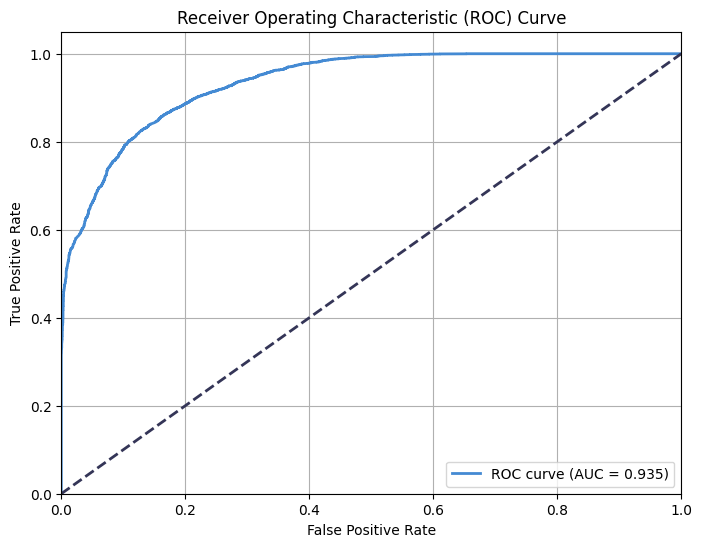

In [88]:
y_probs = best_rf.predict_proba(transformed_X)[:, 1]

fpr, tpr, _ = roc_curve(y, y_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='#448ad3', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='#343557', linestyle='--', lw=2)  # Diagonal line (random guess)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

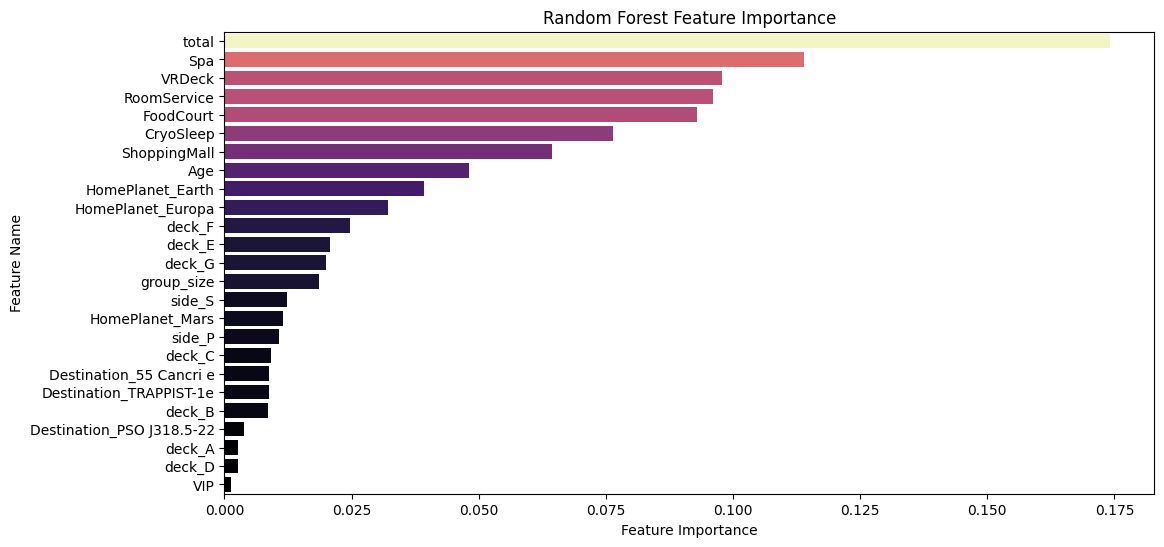

In [89]:
importances = best_rf.named_steps["clf"].feature_importances_
feature_names = transformed_X.columns

indices = np.argsort(importances)[::-1]
sorted_features = [feature_names[i] for i in indices]

plt.figure(figsize=(12, 6))
ax = sns.barplot(x=importances[indices], y=sorted_features, hue=importances[indices], palette="magma")
ax.set(xlabel="Feature Importance", ylabel="Feature Name", title="Random Forest Feature Importance")
ax.get_legend().set_visible(False);

# Kaggle Submission

In [90]:
preprocessor = make_pipeline(
    FunctionTransformer(preprocess_data, validate=False),
    FunctionTransformer(lambda df: df.drop(columns_to_drop, axis=1)),
    FunctionTransformer(encoder_f, validate=False),
)

submission_id = test_data.PassengerId
transformed_test_data = preprocessor.fit_transform(test_data)

In [91]:
predictions = best_rf.predict(transformed_test_data)

n_predictions = (predictions > 0.5).astype(bool)
output = pd.DataFrame({'PassengerId': submission_id, 'Transported': n_predictions})

output.head()

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True


In [92]:
sample_submission_df = pd.read_csv('data/sample_submission.csv')
sample_submission_df['Transported'] = n_predictions
sample_submission_df.to_csv('data/submission.csv', index=False)
sample_submission_df.head()

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True


The CSV file was submitted to the Kaggle competition (https://www.kaggle.com/competitions/spaceship-titanic/overview). Final score 0.79822.

# Project Summary

Overall 50.36% of passengers were transported. Data analysis showed some tendencies for being transported. For example, 81.76% of passengers in cryo sleep, 65.88% of passengers whose home planet is Europa, 61% whose destination was 55 Cancri e, 73.43% from deck B and 68.01% from deck C were transported. People who were below of age of 18, were more frequently transported. Also, ones who didn't spent any money at the any of the attractions were more likely to be transported as well (78.65% of ones who didn't spend any money were transported, who only 29.86% of those who did were).

There was some negative correlations between being transported and spending money for room service, at spa and VR deck, and total spending. 
Also, we can see positive correlation between cryo sleep being transported (0.46). Also there are negative correlations with spending money at any of the attractions and being transported (lower than -0.23). There are also weak positive correlations for home planet Europa, destination 55 Cancri e, decks B and C, and being on Starboard side (between 0.1 and 0.2). There are weak negative correlations for home planet Earth, being on Port side, destination TRAPPIST-1e, decks E and F (between -0.17 and -0.08). These correlations might indicate certain locations on the star ship which were more affected by the anomaly than other. For example, leaving your cabin and going to any of the attractions, gives you better chances to not be transported by the anomaly, compared to passengers who were in cryo sleep and not moving.

All of the features were tested for if they are significant in comparing transferred and not transferred passengers. For passengers age t-test was used because it is distributed normally. For rest of numerical features hypothesis testing I used Mann-Whitney U Test. Overall, all of the features were statistically important when it comes to transporting the passengers.

For binary features, chi-square test was used, to check if there is a statistical difference in frequency of transportation. In majority of cases the results are statistically significant. We have failed to show statistical difference for the passenger is more likely to be transported or not, if they are traveling from Mars, towards destination PSO J318.5-22, their cabins are in deck D, A or G. It is worth mentioning that for cabins in deck D, p value (0.00176) is close to our set significance level (0.00161).

For modeling part, the goal is to create a model which has higher accuracy than baseline simple model - logistic regression. Random forest and support vector machine (SVM) methods were used. For hyper parameter tuning, firstly randomized search was used, and afterwards selection was finished using grid search. Overall, random forest model outperformed SVM and had accuracy of 0.85 in validation set, which was higher than set threshold of 0.8 by logistic regression model.

The goal for Kaggle competition submission is to have accuracy score of 0.79 or above. The prediction was made using the model and the final score is 0.79822.

Overall, the model performs well to split transported and not transported passengers using the given data and will be useful in helping to determine if the passenger was transported or not. 

# Suggestions for improvement 

- Create a function which automatically picks correlation coeficient to calculate depending on the value of the variables.
- Use dimension reduction algorithm.
- Create new features by combining existing ones (for example, perhaps there is an interaction between deck and home planet).
- Try polynomial features for potential non-linear relationships.
- Try to use log scale for money since there are a lot of outliers.
- Use K-Means or DBSCAN (Density-Based Spatial Clustering of Applications with Noise) to find hidden groups among passengers (e.g., spending behavior, travel habits). Add cluster labels as new features.
- Try different ways of handling missing values, instead of just imputing the most common value or 0. Tyr handling missing values with predictive models instead of imputing missing values with most common value, train models to predict missing values based on other features. 
- Try balancing techniques (like SMOTE), since some of the categories are rare and there's imbalance in the dataset (for example there are only around 200 VIP passengers compared to overall 8000). Downsample or upsample to balance the dataset and avoid model bias toward majority classes.
- Compare model performance on different subsets. Does the model perform better for certain groups (e.g., VIP vs. non-VIP, different decks, different spending levels)? Check if the model has bias toward specific demographics.
- Try more different modeling methods: K-Nearest Neighbors, boosting techniques like XGBoost, LightGBM.
- Do feature selection and identify, which features contribute most and remove redundant ones.
- Instead of grid search or Randomized Search, use Bayesian Optimization for smarter hyper parameter tuning.